# LoRA adapter caching, milestone 3: calibrated replay, oracle and ablations
**CSCI 5144 Cloud Computing, Fall 2026.** Quenton Ni, Theo Nguyen, Sudeep Srisailapu, Tien Cao

**Research question (proposal §2).** Under what workload conditions does predictive LoRA adapter caching beat vLLM's reactive
LRU caching, and when do prediction errors and prefetch overhead outweigh the benefit?

**Where we are.**
* **Milestone 1** measured the best case: one avoided adapter load saves about 8 ms of time-to-first-token (TTFT).
* **Milestone 2** replayed realistic traffic. Naive EWMA prefetching was *worse than doing nothing* in 12 of 14 cells:
  4–6× more adapter loads, 85% of prefetches wasted. The run also revealed four calibration mistakes, explained in the next cell.
* **This notebook** fixes those mistakes and asks the follow-up questions:
  1. **Which part of prefetching causes the harm?** Ablation: EWMA with only the "don't evict in-use adapters" rule (R1).
  2. **How much is there to gain at all?** An **oracle** that knows the future, under the same execution rules.
  3. **How does the answer change with load?** Load levels set *relative to measured capacity*, plus 2 vs 4 GPU slots.
  4. **Is the result an artifact of eager mode?** An optional CUDA-graphs engine mode, for a hardware/configuration comparison.

  The transition (Markov) and logistic-regression predictors from proposal §4.3 are deliberately left out of this milestone.
  The policy design in Part 3 has a slot for them, and 3.4 explains how to add one.

| Part | What it does | Runs on | Time |
|---|---|---|---|
| 1. Setup | Workspace, install vLLM 0.32.0, configuration and experiment plan | CPU/GPU | 3–5 min first time |
| 2. Workloads | Synthetic generator (5 factors) + Azure Functions 2021 trace, generated at any arrival rate | CPU | < 1 min |
| 3. Policies | 2 predictors (EWMA, oracle) × 3 execution rules, plus LRU; derivation of the cost rule; unit checks | CPU | seconds |
| 4. Simulator | Queue-aware simulator: screens all 7 policies, load sweep, skew × locality map | CPU | ~1 min |
| 5. GPU harness | In-process vLLM, residency probe, replay loop, milestone-1 replication | GPU | ~2 min |
| 6. Calibrate and run | Measure capacity per slot count, then run the experiment plan (resumable) | GPU | see presets |
| 7. Results | Validity checks, calibration, paired comparisons, 9 figures, simulator validation, auto-written findings | CPU | seconds |
| 8. Presenting | Slide order, limitations, next steps, export | n/a | n/a |

**Plan presets** (set `PLAN_PRESET` in 1.4). Time is GPU time on an L4 in eager mode:
`'quick'` ≈ 20 min (smoke test / hardware check) · `'standard'` ≈ 80 min (default) · `'full'` ≈ 2.5 h (3 seeds on the main block).

**How to run:** Colab → Runtime → Change runtime type → **GPU (L4)** → Runtime → **Run all**.
If Colab disconnects, set `RESUME_RUN_DIR` in the first code cell to the run folder and Run all again; completed runs are skipped.

### What changed since milestone 2, and why
**The four calibration mistakes.** All four came from one wrong guess. I assumed an engine step takes ~20 ms; the L4 in eager
mode actually took **~100–120 ms**. A lone 64-token request needs ~75 ms to its first token, so a 16-token request occupies the engine for ~2 s.

| Milestone-2 mistake | Consequence | Fix in this notebook |
|---|---|---|
| Fixed arrival rate (4 req/s) chosen from the guessed step time | 2-slot runs were overloaded (median TTFT 0.4–1.8 s), so an 8 ms miss was invisible in the latency | **Measure capacity** per slot count (6.1) and run at load levels defined as fractions of it (light/moderate/heavy) |
| Load check used "% of time the engine is busy" | With continuous batching some request is nearly always decoding, so it read 97–99% even when healthy | Capacity is defined by **median TTFT vs unloaded TTFT** (the "knee") |
| Simulator: requests in flight for 0.4 s, and no batch model | It predicted EWMA would help; on the GPU it caused 2.5–5× more loads | **Queue-aware simulator**: running requests hold their adapters, ≤ S distinct adapters per batch, service time from measured step time |
| Admission rule R3 ("≤ 4 in flight") set by hand | Normal concurrency was ~6, so it blocked almost every prefetch; admission never got to act | Replaced by a **cost rule derived from how vLLM loads adapters** (Part 3), which adapts to load automatically |

**A key fact the derivation rests on** (checked in the vLLM 0.32 source): an adapter load runs ~7 ms of host-side copying
*on the engine's single thread*. Its GPU copies are queued on the same CUDA stream as the forward pass. So **any load, demand or
prefetch, stalls every request in flight**. Under continuous load, a correct prefetch doesn't hide the load; it only moves it earlier.
That saves the one request that would have missed, while charging everyone already in flight. Prefetching is only free in **idle time**.
This explains milestone 2, and it predicts where prediction *can* help: light load and bursty traffic with gaps.

**Other improvements:**
* **Primary metrics changed.** Mean and p95 TTFT, plus **load delay per request**: activation time × requests in flight, averaged
  over requests, which is the latency cost of loads directly. Also **end-to-end latency**, because a prefetch can lower TTFT while
  slowing everyone's decode. Hit-at-arrival is kept but secondary: under queueing, being resident when a request *arrives* is not
  the same as being resident when it is *scheduled*.
* **Repeated seeds and paired statistics.** Every policy replays the same trace. Deltas vs LRU are paired per seed, CIs are taken across
  seeds, and sign tests run across all cells.
* **Drift recovery** is measured with cumulative demand loads (smooth) instead of 3-second hit-rate bins (noisy).
* **Milestone-1 replication** now runs for every slot count, and reports the miss cost relative to the decode step time.
* **Resume support, bf16 on GPUs that support it** (removes milestone 2's flood of dtype warnings), quieter downloads.

## Background and key terms
| Term | Meaning in this project |
|---|---|
| **LoRA adapter** | Small low-rank weight deltas: rank 8 on `q_proj` and `v_proj`, 2.18 MB each, customising one shared base model (Qwen2.5-1.5B). |
| **CPU cache** | All 8 adapters stay in host memory (`max_cpu_loras=8`), so there are **no disk loads** during measurements. |
| **GPU slot** | vLLM keeps at most `max_loras` adapters on the GPU (2 or 4 here). It also allows at most that many **distinct adapters per batch**, so slots limit batching as well as caching. |
| **Activation / load** | Copying an adapter from the CPU cache into a GPU slot (~7 ms on the L4, mostly host-side Python). With full slots, vLLM's **LRU** evicts the least recently used adapter. Every engine step re-touches the adapters in the running batch. |
| **Demand load (miss)** | An activation inside an engine step because a scheduled request needs the adapter. The whole batch waits. |
| **Prefetch** | An activation a policy triggers between steps with vLLM's own `add_lora()`. vLLM still picks the victim by LRU. |
| **Touch** | `add_lora()` on an already-resident adapter: nothing is copied, it just becomes most recently used. Used to steer which adapter LRU evicts. |
| **Useful / wasted prefetch** | Useful: a step used the adapter before it was evicted. Wasted: evicted, or the run ended, first. |
| **Prefetch-induced load** | A demand load of an adapter within 2 s of a prefetch evicting it: a guess that pushed out something still needed. |
| **Load delay per request** | Σ over activations of (activation ms × requests in flight at that moment) ÷ requests. The average latency each request pays for adapter loads. |
| **Capacity knee** | The highest arrival rate (uniform popularity, LRU) at which median TTFT stays within 2× the unloaded TTFT. Load levels are fractions of it. |
| **Oracle** | A predictor that reads the trace's future. It bounds what *any* predictor could achieve under the same execution rules. |
| **Eager vs CUDA graphs** | Eager mode launches every GPU kernel from Python (slow steps, used in milestones 1–2). CUDA graphs replay pre-recorded kernel sequences (fast steps). This changes how large a load is *relative to* a step. |

---
# Part 1: Setup
### 1.1 Workspace, GPU check, resume
Every run creates `lora_cache_lab/results/m3_<timestamp>/`. All CSVs, figures and findings go there, and results are rewritten
after every replay, so a disconnect loses at most the replay in progress. **To resume**, set `RESUME_RUN_DIR` to that folder
and Run all. Calibration, diagnostics and completed replays are reloaded and skipped.

In [1]:
# ---- To continue an interrupted run, put its folder here and Run all ----
RESUME_RUN_DIR = None     # e.g. '/content/lora_cache_lab/results/m3_20261104T101500Z'

import gc
import heapq
import itertools
import json
import math
import os
import random
import shutil
import subprocess
import sys
import time
import zipfile
from collections import Counter, OrderedDict, defaultdict, deque
from datetime import datetime, timezone
from pathlib import Path

os.environ.setdefault('HF_HUB_DISABLE_PROGRESS_BARS', '1')   # keep download progress bars out of the outputs
IN_COLAB = 'google.colab' in sys.modules
LAB = (Path('/content') if Path('/content').is_dir() else Path.cwd()) / 'lora_cache_lab'
LAB.mkdir(parents=True, exist_ok=True)
if RESUME_RUN_DIR:
    RUN_DIR = Path(RESUME_RUN_DIR)
    if not RUN_DIR.is_dir():
        raise FileNotFoundError(f'RESUME_RUN_DIR does not exist: {RUN_DIR}')
else:
    RUN_DIR = LAB / 'results' / ('m3_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ'))
FIG_DIR = RUN_DIR / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)


def nvidia_smi_summary():
    """'name, memory, driver' for the GPU, or None without an NVIDIA GPU."""
    exe = shutil.which('nvidia-smi')
    if not exe:
        return None
    out = subprocess.run([exe, '--query-gpu=name,memory.total,driver_version', '--format=csv,noheader'],
                         text=True, capture_output=True)
    return out.stdout.strip().splitlines()[0] if out.returncode == 0 and out.stdout.strip() else None


GPU_SUMMARY = nvidia_smi_summary()
HAS_GPU = GPU_SUMMARY is not None
GPU_NAME = GPU_SUMMARY.split(',')[0].strip() if GPU_SUMMARY else 'no GPU'
print('Workspace :', LAB)
print('This run  :', RUN_DIR, '(resuming)' if RESUME_RUN_DIR else '(new)')
print('Python    :', sys.version.split()[0], '| Colab:', IN_COLAB)
print('GPU       :', GPU_SUMMARY or 'none detected. GPU parts (5-6) will be skipped; CPU parts still run')

Workspace : /content/lora_cache_lab
This run  : /content/lora_cache_lab/results/m3_20261103T011025Z (new)
Python    : 3.13.16 | Colab: True
GPU       : NVIDIA L4, 23034 MiB, 580.82.07


### 1.2 Install vLLM 0.32.0
Same pinned version as milestone 2. The residency probe reads vLLM internals, which were checked against the 0.32.0 source:
`LRUCacheLoRAModelManager.activate_adapter`, the LRU `_active_adapters.order`, `set_active_adapters` (called every step), and
`add_lora()` activating a CPU-cached adapter on the GPU. Installing vLLM also replaces Colab's PyTorch with vLLM's pinned one (2.13).

In [2]:
VLLM_VERSION = '0.32.0'


def installed_version(package):
    from importlib.metadata import PackageNotFoundError, version
    try:
        return version(package)
    except PackageNotFoundError:
        return None


if not HAS_GPU:
    print('No GPU, so vLLM is not installed. The CPU-only parts (2-4) still run.')
elif installed_version('vllm') == VLLM_VERSION:
    print(f'vLLM {VLLM_VERSION} already installed; skipping.')
else:
    print(f'Installing vLLM {VLLM_VERSION} and its pinned PyTorch. This takes a few minutes...')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', f'vllm=={VLLM_VERSION}'], check=True)
    print('Done. If a later cell fails with a NumPy/PyTorch binary-compatibility error, use '
          'Runtime → Restart session and Run all again (this cell then skips itself).')

Installing vLLM 0.32.0 and its pinned PyTorch. This takes a few minutes...
Done. If a later cell fails with a NumPy/PyTorch binary-compatibility error, use Runtime → Restart session and Run all again (this cell then skips itself).


### 1.3 Analysis libraries and plotting style
Each policy keeps one colour across every figure. SciPy (preinstalled in Colab) is used for t-based confidence intervals when available.

In [3]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
try:
    from scipy import stats as sstats
except ImportError:
    sstats = None

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'font.size': 10})

POLICY_COLORS = {'LRU': '#6b7280', 'EWMA': '#d97706', 'EWMA+R1': '#a855f7', 'EWMA+admission': '#2563eb',
                 'Oracle': '#86efac', 'Oracle+R1': '#22c55e', 'Oracle+admission': '#059669'}


def policy_color(name):
    return POLICY_COLORS.get(name, plt.cm.tab20(sum(map(ord, name)) % 20))


def savefig(fig, name):
    """Save a figure as PNG in this run's figures folder, then display it."""
    path = FIG_DIR / f'{name}.png'
    fig.savefig(path, dpi=160, bbox_inches='tight')
    print('saved figure:', path.relative_to(LAB))
    plt.show()


print('numpy', np.__version__, '| pandas', pd.__version__, '| matplotlib', matplotlib.__version__,
      '| scipy', 'yes' if sstats else 'no')

numpy 2.4.6 | pandas 2.2.3 | matplotlib 3.10.0 | scipy yes


### 1.4 Configuration and experiment plan
Everything that changes a result is in `CONFIG`, which is saved as `config.json`.

**Load levels are relative.** `light`, `moderate` and `heavy` are 0.35, 0.7 and 1.0 × the capacity knee measured in 6.1 *for that slot
count on this GPU and engine mode*. This makes eager and CUDA-graph runs, or L4 and A100 runs, comparable at the same relative load.
Before the GPU measures anything, the CPU parts use **prior** capacities taken from the milestone-2 L4 run (labelled as such).

**The plan** is a list of blocks. Each block runs every scenario × policy × seed at one slot count and load level:
* `main`: 4 slots, moderate load, all scenarios. The headline comparison.
* `load`: 4 slots, light and heavy load, two predictable scenarios. Together with `main`'s moderate runs, this is the load sweep.
* `slots2`: 2 slots, moderate load. The cache-pressure comparison.

**GPU policies** (5): `LRU`, `EWMA` (naive, as in milestone 2), `EWMA+R1` (ablation), `EWMA+admission` (cost rule), and
`Oracle+admission` (headroom). The simulator (Part 4) also runs `Oracle` and `Oracle+R1`, to show the headroom under each rule.

In [4]:
PLAN_PRESET = 'standard'   # 'quick' (~20 min GPU) | 'standard' (~80 min) | 'full' (~2.5 h)
ENGINE_MODE = 'eager'      # 'eager' (as milestones 1-2) | 'cuda_graphs' (faster steps; see Part 5)

CONFIG = {
    # ---- Model and serving ----
    'model_id': 'Qwen/Qwen2.5-1.5B-Instruct',
    'revision': 'main',                # resolved to an exact commit and recorded
    'vllm_version': VLLM_VERSION,
    'engine_mode': ENGINE_MODE,
    'n_adapters': 8, 'rank': 8,
    'max_num_seqs': 16, 'max_num_batched_tokens': 2048, 'max_model_len': 512,
    'gpu_memory_utilization': 0.40,    # low on purpose: a second engine must fit after the first shuts down
    'prompt_tokens': 64, 'output_tokens': 16,
    'seed': 7,                         # seed index 0 reproduces milestone 2's traces
    # ---- Milestone-1 replication (Part 5.7), run once per slot count ----
    'diag_repeats': 20, 'diag_gap_s': 0.30, 'diag_prefetch_offset_s': 0.05,
    # ---- Capacity calibration (Part 6.1) ----
    'probe_rates': [0.5, 1.0, 1.5, 2.0, 3.0, 4.0, 6.0, 8.0, 12.0],   # req/s, uniform popularity, LRU
    'probe_duration_s': 20.0,
    'knee_ttft_factor': 2.0,           # knee = highest rate with median TTFT ≤ 2 × unloaded TTFT
    'load_levels': {'light': 0.35, 'moderate': 0.70, 'heavy': 1.00},
    # Priors used only before the GPU has measured anything (from the milestone-2 L4 run; cuda_graphs values are guesses)
    'prior_calibration': {
        'eager':       {'knee_rate': {'2': 1.5, '4': 4.0}, 'step_ms': 110.0, 'unloaded_ttft_ms': 80.0, 'activation_ms': 7.5},
        'cuda_graphs': {'knee_rate': {'2': 3.0, '4': 8.0}, 'step_ms': 40.0, 'unloaded_ttft_ms': 35.0, 'activation_ms': 7.5},
    },
    # ---- Policies (Part 3) ----
    'tick_s': 0.25,                    # predictors update (and may prefetch) every tick
    'ewma_alpha': 0.10,                # per-tick smoothing; time constant = tick_s / alpha = 2.5 s
    'min_rate': 0.05,                  # req/s; never prefetch an adapter the predictor has (almost) never seen
    'horizon_s': 2.0,                  # "soon" for the cost rule, induced-load accounting and the oracle
    'admit_margin': 0.10,              # cost rule: required expected saving, in units of one load
    'max_prefetch_per_s': 2.0,         # R4 token-bucket budget for speculative loads
    # ---- Simulator (Part 4) ----
    'sim_seeds': 10,
    # ---- Azure Functions 2021 trace (Part 2.3) ----
    'azure_url': 'https://raw.githubusercontent.com/Azure/AzurePublicDataset/master/data/'
                 'AzureFunctionsInvocationTraceForTwoWeeksJan2021.rar',
    'azure_window_s': 180.0, 'azure_window_start_s': None,
}

ALL_SCENARIOS = ['uniform_steady', 'skewed_steady', 'skewed_bursty', 'skewed_local',
                 'drift_abrupt', 'drift_gradual', 'azure_2021']
GPU_POLICIES = ['LRU', 'EWMA', 'EWMA+R1', 'EWMA+admission', 'Oracle+admission']
SIM_POLICIES = ['LRU'] + [p + r for p in ('EWMA', 'Oracle') for r in ('', '+R1', '+admission')]

PRESETS = {
    'quick': {'duration_s': 30.0, 'blocks': [
        dict(name='main', slots=4, levels=['moderate'], scenarios=['skewed_bursty', 'drift_abrupt', 'azure_2021'], seeds=[0])]},
    'standard': {'duration_s': 45.0, 'blocks': [
        dict(name='main', slots=4, levels=['moderate'], scenarios=ALL_SCENARIOS, seeds=[0]),
        dict(name='load', slots=4, levels=['light', 'heavy'], scenarios=['skewed_steady', 'skewed_bursty'], seeds=[0]),
        dict(name='slots2', slots=2, levels=['moderate'], scenarios=['skewed_steady', 'skewed_bursty', 'drift_abrupt'], seeds=[0])]},
    'full': {'duration_s': 45.0, 'blocks': [
        dict(name='main', slots=4, levels=['moderate'], scenarios=ALL_SCENARIOS, seeds=[0, 1, 2]),
        dict(name='load', slots=4, levels=['light', 'heavy'], scenarios=['skewed_steady', 'skewed_bursty'], seeds=[0]),
        dict(name='slots2', slots=2, levels=['moderate'], scenarios=ALL_SCENARIOS, seeds=[0])]},
}
PLAN = PRESETS[PLAN_PRESET]['blocks']
CONFIG.update(plan_preset=PLAN_PRESET, duration_s=PRESETS[PLAN_PRESET]['duration_s'], plan=PLAN, gpu_policies=GPU_POLICIES)
SCENARIOS_IN_PLAN = [s for s in ALL_SCENARIOS if any(s in b['scenarios'] for b in PLAN)]
SLOT_CONFIGS = sorted({b['slots'] for b in PLAN})
ADAPTER_IDS = list(range(1, CONFIG['n_adapters'] + 1))
assert CONFIG['prompt_tokens'] + CONFIG['output_tokens'] <= CONFIG['max_model_len']
assert all(1 <= s < CONFIG['n_adapters'] for s in SLOT_CONFIGS)


def plan_runs():
    """Every (block, slots, level, scenario, seed_index, policy) replay in the plan."""
    return [(b['name'], b['slots'], lvl, scen, seed, pol)
            for b in PLAN for lvl in b['levels'] for scen in b['scenarios'] for seed in b['seeds'] for pol in GPU_POLICIES]


config_path = RUN_DIR / 'config.json'
if RESUME_RUN_DIR and config_path.exists():
    saved = json.loads(config_path.read_text())
    changed = [k for k in CONFIG if saved.get(k) != CONFIG[k]]
    if changed:
        print('WARNING: config differs from the run being resumed in:', changed)
else:
    config_path.write_text(json.dumps(CONFIG, indent=2))
n_runs = len(plan_runs())
est_min = n_runs * (CONFIG['duration_s'] + 4) / 60 + len(SLOT_CONFIGS) * 6
print(f'Preset {PLAN_PRESET!r}, engine mode {ENGINE_MODE!r}: {n_runs} GPU replays over slot counts {SLOT_CONFIGS}; '
      f'estimated GPU time ≈ {est_min:.0f} min')
for b in PLAN:
    print(f"  block {b['name']:7s} slots={b['slots']} levels={b['levels']} seeds={b['seeds']} scenarios={b['scenarios']}")

Preset 'quick', engine mode 'eager': 15 GPU replays over slot counts [4]; estimated GPU time ≈ 14 min
  block main    slots=4 levels=['moderate'] seeds=[0] scenarios=['skewed_bursty', 'drift_abrupt', 'azure_2021']


### 1.5 Calibration bookkeeping
`calib(slots)` returns the measured capacity and timings for a slot count once Part 6.1 has measured them, and the prior until then.
`level_rate(slots, level)` turns a load level into an arrival rate. `service_s(slots, rate)` is how long a request occupies the engine
(17 steps × step time at that rate), which the simulator needs.

In [5]:
CAL_PATH = RUN_DIR / 'calibration.json'
CAL = json.loads(CAL_PATH.read_text()) if CAL_PATH.exists() else {}     # str(slots) -> measured calibration
PRIOR = CONFIG['prior_calibration'][ENGINE_MODE]


def calib(slots):
    """Measured calibration for this slot count if available, else the prior (marked source='prior')."""
    if str(slots) in CAL:
        return CAL[str(slots)]
    return {'source': 'prior', 'knee_rate': PRIOR['knee_rate'].get(str(slots), PRIOR['knee_rate']['4']),
            'step_ms': PRIOR['step_ms'], 'unloaded_ttft_ms': PRIOR['unloaded_ttft_ms'],
            'activation_ms': PRIOR['activation_ms'], 'probe': []}


def level_rate(slots, level):
    return round(CONFIG['load_levels'][level] * calib(slots)['knee_rate'], 3)


def service_s(slots, rate):
    """Seconds a request holds the engine: (output tokens + 1 prefill) × step time measured near this rate."""
    c = calib(slots)
    probe = [p for p in c.get('probe', []) if p.get('step_ms_mean') == p.get('step_ms_mean')]
    step = np.interp(rate, [p['rate'] for p in probe], [p['step_ms_mean'] for p in probe]) if probe else c['step_ms']
    return (CONFIG['output_tokens'] + 1) * float(step) / 1000


for s in sorted(set(SLOT_CONFIGS) | {2, 4}):
    c = calib(s)
    print(f"{s} slots ({c['source']}): knee {c['knee_rate']} req/s → " +
          ', '.join(f'{lvl} {level_rate(s, lvl)} req/s' for lvl in CONFIG['load_levels']) +
          f" | service ≈ {service_s(s, level_rate(s, 'moderate')):.2f} s")

2 slots (prior): knee 1.5 req/s → light 0.525 req/s, moderate 1.05 req/s, heavy 1.5 req/s | service ≈ 1.87 s
4 slots (prior): knee 4.0 req/s → light 1.4 req/s, moderate 2.8 req/s, heavy 4.0 req/s | service ≈ 1.87 s


---
# Part 2: Workloads
### 2.1 Synthetic workload generator
Unchanged from milestone 2, except that the **arrival rate is now an argument**, because it comes from calibration.
Proposal §4.2's factors, each varied independently:

| Factor | Argument | Model |
|---|---|---|
| **Arrival pattern** | `burst` | `None` = Poisson. Otherwise on/off (MMPP-2): "on" periods `on_mult`× faster, exponential on/off lengths, same long-run mean rate. |
| **Popularity skew** | `zipf_s` | P(rank *k*) ∝ 1/*k*^s. s = 0 is uniform; s = 1.2 gives the top adapter ~43% of requests (8 adapters). |
| **Temporal locality** | `locality` | With probability `p_repeat`, reuse one of the last `window` adapters. |
| **Cache capacity** | (plan) | 2 or 4 GPU slots. |
| **Drift** | `drift` | The popularity ranking reverses: `abrupt` at `at_frac` × duration, or `gradual` between `at_frac` and `end_frac`. |
| **Load** | `rate` | Requests per second, from the load level (new). |

Seed index *i* uses RNG seed `CONFIG['seed'] + i`, so every policy, and the simulator, sees **exactly** the same requests.

In [6]:
SCENARIO_SPECS = {
    'uniform_steady': dict(zipf_s=0.0),
    'skewed_steady':  dict(zipf_s=1.2),
    'skewed_bursty':  dict(zipf_s=1.2, burst=dict(on_mult=4.0, mean_on_s=3.0, mean_off_s=6.0)),
    'skewed_local':   dict(zipf_s=0.6, locality=dict(p_repeat=0.5, window=3)),
    'drift_abrupt':   dict(zipf_s=1.2, drift=dict(kind='abrupt', at_frac=0.5)),
    'drift_gradual':  dict(zipf_s=1.2, drift=dict(kind='gradual', at_frac=0.3, end_frac=0.7)),
}


def zipf_probs(n, s):
    w = 1.0 / np.arange(1, n + 1) ** s
    return w / w.sum()


def arrival_times(rng, duration_s, rate, burst=None):
    """Poisson arrivals, or a two-state on/off process with the same long-run mean rate."""
    if burst is None:
        n = rng.poisson(rate * duration_s)
        return np.sort(rng.uniform(0, duration_s, n)), np.zeros(n, dtype=bool)
    on_frac = burst['mean_on_s'] / (burst['mean_on_s'] + burst['mean_off_s'])
    off_rate = rate / (on_frac * burst['on_mult'] + (1 - on_frac))
    on_rate = burst['on_mult'] * off_rate
    times, flags, t, on = [], [], 0.0, False
    while t < duration_s:
        end = min(t + rng.exponential(burst['mean_on_s'] if on else burst['mean_off_s']), duration_s)
        k = rng.poisson((on_rate if on else off_rate) * (end - t))
        times.extend(rng.uniform(t, end, k))
        flags.extend([on] * k)
        t, on = end, not on
    order = np.argsort(times)
    return np.asarray(times, dtype=float)[order], np.asarray(flags, dtype=bool)[order]


def make_synthetic_trace(name, seed, rate, duration_s=None, zipf_s=1.0, burst=None, locality=None, drift=None):
    """One row per request: arrival_s and adapter_id (1..n). Adapter 1 is most popular before any drift."""
    duration_s = duration_s or CONFIG['duration_s']
    n = CONFIG['n_adapters']
    rng = np.random.default_rng(seed)
    times, in_burst = arrival_times(rng, duration_s, rate, burst)
    p_old = zipf_probs(n, zipf_s)
    p_new = p_old[::-1]

    def drift_weight(t):
        if drift is None:
            return 0.0
        start = drift['at_frac'] * duration_s
        if drift['kind'] == 'abrupt':
            return float(t >= start)
        return float(np.clip((t - start) / (drift['end_frac'] * duration_s - start), 0.0, 1.0))

    adapters, weights, repeats = [], [], []
    for t in times:
        w = drift_weight(t)
        if locality and adapters and rng.random() < locality['p_repeat']:
            adapters.append(int(rng.choice(adapters[-locality['window']:])))
            repeats.append(True)
        else:
            adapters.append(int(rng.choice(n, p=(1 - w) * p_old + w * p_new)) + 1)
            repeats.append(False)
        weights.append(w)
    return pd.DataFrame({'arrival_s': times, 'adapter_id': np.asarray(adapters, dtype=int), 'drift_weight': weights,
                         'in_burst': in_burst, 'locality_repeat': repeats, 'scenario': name})


NOMINAL_SLOTS = 4 if 4 in SLOT_CONFIGS else SLOT_CONFIGS[0]
NOMINAL_RATE = level_rate(NOMINAL_SLOTS, 'moderate')
print(f'Nominal rate for the previews below: {NOMINAL_RATE} req/s ({NOMINAL_SLOTS} slots, moderate, {calib(NOMINAL_SLOTS)["source"]})')

Nominal rate for the previews below: 2.8 req/s (4 slots, moderate, prior)


### 2.2 What the synthetic traces look like
Dots are requests coloured by adapter (y = adapter ID); the grey line is requests per second. Look for the hot rows (adapters 1–2)
in the skewed traces, the dense columns in `skewed_bursty`, and the hot set moving from bottom to top in the drift traces.

saved figure: results/m3_20261103T011025Z/figures/figW1_synthetic_traces.png


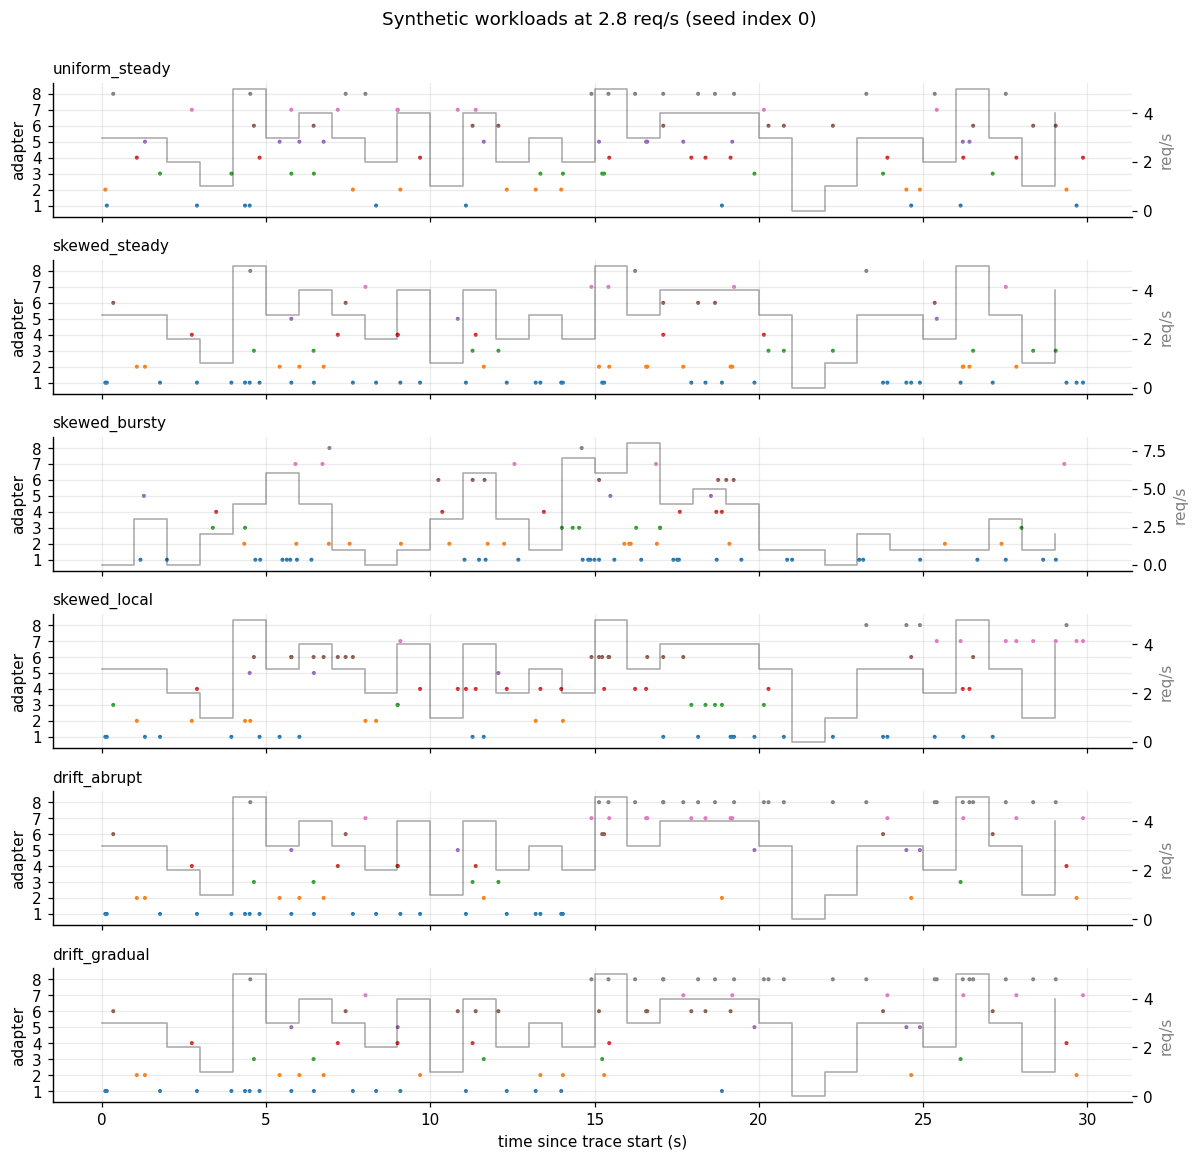

,requests,top_adapter_share,peak_req_per_s
scenario,,,
uniform_steady,87,0.16,5
skewed_steady,87,0.41,5
skewed_bursty,81,0.42,8
skewed_local,87,0.26,5
drift_abrupt,87,0.26,5
drift_gradual,87,0.25,5


In [7]:
def plot_traces(traces, title, name):
    names = list(traces)
    fig, axes = plt.subplots(len(names), 1, figsize=(11, 1.75 * len(names)), sharex=True, squeeze=False)
    for ax, scen in zip(axes[:, 0], names):
        df = traces[scen]
        ax.scatter(df.arrival_s, df.adapter_id, s=7, c=df.adapter_id, cmap='tab10', vmin=1, vmax=10, linewidths=0)
        ax.set_yticks(ADAPTER_IDS)
        ax.set_ylim(0.3, CONFIG['n_adapters'] + 0.7)
        ax.set_ylabel('adapter')
        ax.set_title(scen, loc='left', fontsize=10)
        per_s = np.histogram(df.arrival_s, bins=np.arange(0, math.ceil(CONFIG['duration_s']) + 1))[0]
        ax2 = ax.twinx()
        ax2.step(np.arange(len(per_s)), per_s, where='post', color='black', alpha=0.35, lw=1)
        ax2.set_ylabel('req/s', color='gray')
        ax2.grid(False)
    axes[-1, 0].set_xlabel('time since trace start (s)')
    fig.suptitle(title, y=1.0)
    fig.tight_layout()
    savefig(fig, name)


PREVIEW = {s: make_synthetic_trace(s, CONFIG['seed'], NOMINAL_RATE, **SCENARIO_SPECS[s]) for s in SCENARIO_SPECS}
plot_traces(PREVIEW, f'Synthetic workloads at {NOMINAL_RATE} req/s (seed index 0)', 'figW1_synthetic_traces')
display(pd.DataFrame([{'scenario': s, 'requests': len(df), 'top_adapter_share': round(df.adapter_id.value_counts(normalize=True).iloc[0], 2),
                       'peak_req_per_s': int(np.histogram(df.arrival_s, bins=np.arange(0, CONFIG['duration_s'] + 1))[0].max())}
                      for s, df in PREVIEW.items()]).set_index('scenario'))

### 2.3 Real-trace check: Azure Functions 2021
Unchanged method from milestone 2. No public trace has LoRA adapter IDs, so, following dLoRA and Predictive-LoRA, **each serverless
function stands in for an adapter**. State this assumption on a slide.
1. Download the 18 MB `.rar` once, extract it with `unrar`, and keep `(start time, function)` for 1.98 M invocations and 424 functions.
2. Consider every 3-minute window in which the 8 busiest functions have ≥ 300 requests and each appears ≥ 3 times. Seed index 0 uses
   the window with the **median** top-function share (a typical window). Other seed indices use other candidate windows.
3. Map that window's 8 busiest functions to adapters 1–8, **compress** 180 s into the trace duration, then **thin** to the target rate.
   If the window has too few requests for a high rate, the trace keeps them all and the shortfall is reported.

1,980,951 invocations, 424 functions, 3,451 candidate windows
{
  "window_start_s": 1008420.0,
  "window_start_day": 11.672,
  "window_s": 180.0,
  "time_compression": 6.0,
  "requests_in_window_all_functions": 807,
  "share_of_window_from_top_k": 0.934,
  "thinning_keep_fraction": 0.111,
  "target_rate": 2.8,
  "actual_rate": 2.433
}
saved figure: results/m3_20261103T011025Z/figures/figW2_azure_trace.png


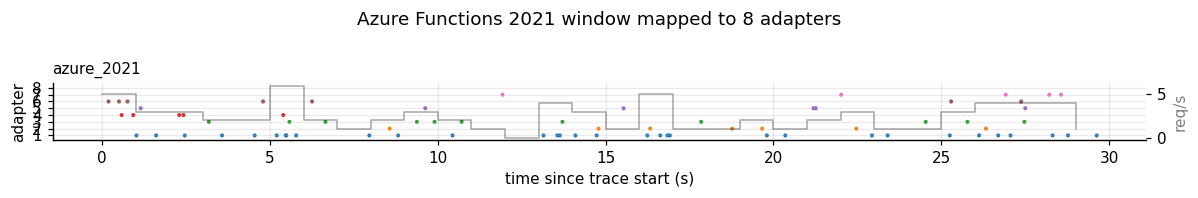

In [8]:
AZURE_DIR = LAB / 'azure'
AZURE_DIR.mkdir(exist_ok=True)
AZURE_COMPACT = AZURE_DIR / 'azure_functions_2021_compact.csv.gz'


def ensure_unrar():
    if not shutil.which('unrar') and shutil.which('apt-get'):
        subprocess.run(['apt-get', 'install', '-y', '-qq', 'unrar'], capture_output=True)
    return shutil.which('unrar')


def load_azure_functions_2021():
    """Compact (start_s, function) table for all invocations; cached after the first call."""
    if AZURE_COMPACT.exists():
        return pd.read_csv(AZURE_COMPACT)
    rar = AZURE_DIR / 'AzureFunctionsInvocationTraceForTwoWeeksJan2021.rar'
    txt = AZURE_DIR / 'AzureFunctionsInvocationTraceForTwoWeeksJan2021.txt'
    if not txt.exists():
        if not rar.exists() or rar.stat().st_size < 1_000_000:
            import urllib.request
            print('Downloading the Azure Functions 2021 trace (~18 MB)...')
            urllib.request.urlretrieve(CONFIG['azure_url'], rar)
        if rar.read_bytes()[:4] != b'Rar!':
            raise RuntimeError(f'{rar} is not a RAR archive; the download probably failed.')
        tool = ensure_unrar()
        if not tool:
            raise RuntimeError(f'`unrar` is unavailable. Extract the archive elsewhere and upload the .txt to {AZURE_DIR}')
        subprocess.run([tool, 'x', '-o+', str(rar), str(AZURE_DIR) + os.sep], check=True, capture_output=True)
    raw = pd.read_csv(txt, dtype={'app': 'category', 'func': 'category'})
    compact = pd.DataFrame({'start_s': (raw['end_timestamp'] - raw['duration']).round(4),
                            'function': raw.groupby(['app', 'func'], observed=True).ngroup().astype('int32')})
    compact.to_csv(AZURE_COMPACT, index=False)
    del raw
    gc.collect()
    return compact


def azure_windows(compact, k, window_s, min_requests):
    """Score every minute-aligned window; keep those with enough top-k traffic."""
    minute = np.clip((compact['start_s'].to_numpy() // 60).astype(int), 0, None)
    func = compact['function'].to_numpy()
    counts = np.zeros((minute.max() + 1, func.max() + 1), dtype=np.int32)
    np.add.at(counts, (minute, func), 1)
    w = int(window_s // 60)
    csum = np.cumsum(counts, axis=0, dtype=np.int64)
    win = csum[w - 1:] - np.vstack([np.zeros((1, counts.shape[1]), dtype=np.int64), csum[:-w]])
    topk = -np.sort(-win, axis=1)[:, :k]
    total = topk.sum(axis=1)
    frame = pd.DataFrame({'start_s': np.arange(len(win)) * 60.0, 'topk_requests': total,
                          'kth_count': topk[:, -1], 'top1_share': topk[:, 0] / np.maximum(total, 1)})
    return frame[(frame.topk_requests >= min_requests) & (frame.kth_count >= 3)].reset_index(drop=True)


def azure_to_trace(compact, start_s, rate, seed, name='azure_2021'):
    window_s, k, duration = CONFIG['azure_window_s'], CONFIG['n_adapters'], CONFIG['duration_s']
    window = compact[(compact.start_s >= start_s) & (compact.start_s < start_s + window_s)]
    top = window['function'].value_counts().head(k)
    mapping = {f: i + 1 for i, f in enumerate(top.index)}
    sub = window[window['function'].isin(mapping)].sort_values('start_s')
    keep_p = min(1.0, rate * duration / max(len(sub), 1))
    sub = sub[np.random.default_rng(seed).random(len(sub)) < keep_p]
    trace = pd.DataFrame({'arrival_s': ((sub.start_s - start_s) * duration / window_s).to_numpy(),
                          'adapter_id': sub['function'].map(mapping).to_numpy().astype(int),
                          'drift_weight': 0.0, 'in_burst': False, 'locality_repeat': False, 'scenario': name})
    info = {'window_start_s': float(start_s), 'window_start_day': round(start_s / 86400, 3), 'window_s': window_s,
            'time_compression': round(window_s / duration, 2), 'requests_in_window_all_functions': int(len(window)),
            'share_of_window_from_top_k': round(float(top.sum()) / max(len(window), 1), 3),
            'thinning_keep_fraction': round(keep_p, 3), 'target_rate': rate,
            'actual_rate': round(len(trace) / duration, 3)}
    return trace, info


AZURE, AZURE_CANDIDATES, AZURE_START = None, None, None
if 'azure_2021' in SCENARIOS_IN_PLAN:
    try:
        AZURE = load_azure_functions_2021()
        AZURE_CANDIDATES = azure_windows(AZURE, CONFIG['n_adapters'], CONFIG['azure_window_s'], 300)
        if CONFIG['azure_window_start_s'] is not None:
            AZURE_START = float(CONFIG['azure_window_start_s'])
        else:
            ranked = AZURE_CANDIDATES.sort_values('top1_share').reset_index(drop=True)
            AZURE_START = float(ranked.loc[len(ranked) // 2, 'start_s'])
        preview, info = azure_to_trace(AZURE, AZURE_START, NOMINAL_RATE, CONFIG['seed'])
        (RUN_DIR / 'azure_window.json').write_text(json.dumps(info, indent=2))
        print(f'{len(AZURE):,} invocations, {AZURE.function.nunique()} functions, {len(AZURE_CANDIDATES):,} candidate windows')
        print(json.dumps(info, indent=2))
        plot_traces({'azure_2021': preview}, 'Azure Functions 2021 window mapped to 8 adapters', 'figW2_azure_trace')
    except Exception as exc:
        print('Azure trace unavailable, so the scenario is skipped everywhere:', repr(exc))
        for b in PLAN:
            b['scenarios'] = [s for s in b['scenarios'] if s != 'azure_2021']
        SCENARIOS_IN_PLAN = [s for s in SCENARIOS_IN_PLAN if s != 'azure_2021']

### 2.4 One function for every trace
`trace_for(scenario, seed_index, rate)` is the only way traces are made, for the simulator, the GPU and the later validation.
That guarantees they all see identical requests. Traces are cached, and every GPU trace is saved to `traces/` in the run folder.

In [9]:
_TRACE_CACHE = {}


def trace_for(scenario, seed_index, rate):
    key = (scenario, int(seed_index), round(float(rate), 4), CONFIG['duration_s'])
    if key not in _TRACE_CACHE:
        seed = CONFIG['seed'] + int(seed_index)
        if scenario == 'azure_2021':
            if AZURE is None:
                raise RuntimeError('Azure trace not loaded')
            start = AZURE_START if seed_index == 0 else float(AZURE_CANDIDATES.sample(1, random_state=seed)['start_s'].iloc[0])
            trace = azure_to_trace(AZURE, start, rate, seed)[0]
        else:
            trace = make_synthetic_trace(scenario, seed, rate, **SCENARIO_SPECS[scenario])
        _TRACE_CACHE[key] = trace.sort_values('arrival_s').reset_index(drop=True)
    return _TRACE_CACHE[key]

---
# Part 3: Policies
### 3.1 Design: a policy = a predictor + an execution rule
Milestone 2 bundled "what will be requested" and "what to do about it" into one class per policy. Here they are separate, so any
predictor can be combined with any rule. That is what makes the ablation and the oracle comparison clean.

**Predictors** estimate each adapter's request rate λ̂ (req/s) and P(requested within the next H = 2 s).

| Predictor | Idea | Source |
|---|---|---|
| **EWMA** | λ̂ ← α·(requests last tick / Δt) + (1−α)·λ̂, updated every 0.25 s; only past requests. P = 1 − e^(−λ̂H). | NIST/SEMATECH exponential smoothing |
| **Oracle** | Reads the trace's actual next H seconds. P = 1 if the adapter is requested then, else 0. | Upper bound for any predictor |

**Execution rules** turn predictions into `add_lora()` calls. All of them consider the top-*k* adapters (k = slots) that are not resident.

| Rule | Prefetch candidate *c* when… |
|---|---|
| **naive** (`EWMA`) | Always. vLLM's LRU evicts whatever is oldest, possibly an adapter the running batch is using. This is milestone 2's policy. |
| **R1** (`+R1`) | Some resident adapter *v* has no queued or running request and is not itself in the top-*k*. Older protected adapters are *touched* first, so LRU evicts exactly *v*. |
| **admission** (`+admission`) | R1, plus the **cost rule** below, plus the **R4 budget** (≤ 2 speculative loads/s). |

### 3.2 The cost rule, derived from how vLLM loads adapters
A load costs about *m* ≈ 7 ms of engine time, during which **all n requests in flight wait** (Part 0). Compare two cases for candidate *c* and victim *v*:
* **Don't prefetch.** If *c* is requested within H (probability P_c), that load happens later inside a step. It delays the requester plus
  everyone else in flight, ≈ *m*(n+1).
* **Prefetch now.** It costs *m*·n immediately. If *v* is requested within H (probability P_v), *v* must be reloaded: ≈ *m*(n+1)·P_v.

Expected saving, in units of *m*: **(n+1)·(P_c − P_v) − n**. Prefetch only if it is ≥ `admit_margin` (0.1). Consequences:
* **Idle engine (n = 0):** prefetch whenever *c* is more likely than *v* to be needed. This is milestone 1's best case.
* **Busy engine (n = 6):** prefetch only if P_c − P_v ≥ 0.87, i.e. *c* is almost certainly needed and *v* almost certainly not.
  Under continuous load, prefetching is nearly zero-sum: the load happens either way, and only the requester's own wait is saved.
* There is no hand-tuned "busy" threshold any more. The rule adapts to load. The `admit_margin` is in interpretable units (one load).

The cost counts all in-flight requests, including ones already decoding. So it is a rule about **total** latency. TTFT alone can look
better than this rule predicts, and that is why end-to-end latency is reported too.

In [10]:
class EWMAPredictor:
    """Per-adapter request rate (req/s): rate ← α · (requests last tick / tick_s) + (1 − α) · rate."""
    name = 'EWMA'

    def __init__(self, cfg):
        self.cfg, self.n = cfg, cfg['n_adapters']
        self.reset()

    def reset(self, trace=None):
        self.rate = np.zeros(self.n + 1)          # index = adapter id; index 0 unused
        self.pending = np.zeros(self.n + 1)

    def observe(self, a, t):
        self.pending[a] += 1

    def close_tick(self, t):
        alpha = self.cfg['ewma_alpha']
        self.rate = alpha * self.pending / self.cfg['tick_s'] + (1 - alpha) * self.rate
        self.pending[:] = 0

    def rates(self):
        return self.rate

    def probs(self):
        """P(requested within horizon_s), assuming Poisson arrivals at the estimated rate."""
        return 1 - np.exp(-self.rates() * self.cfg['horizon_s'])


class OraclePredictor(EWMAPredictor):
    """Knows the future: counts each adapter's actual requests in (now, now + horizon_s]."""
    name = 'Oracle'

    def reset(self, trace=None):
        super().reset(trace)
        self.times = np.zeros(0) if trace is None else trace['arrival_s'].to_numpy(float)
        self.adapters = np.zeros(0, dtype=int) if trace is None else trace['adapter_id'].to_numpy(int)
        self.now = 0.0

    def close_tick(self, t):
        super().close_tick(t)
        self.now = t

    def _future_counts(self):
        lo, hi = np.searchsorted(self.times, [self.now, self.now + self.cfg['horizon_s']], side='right')
        return np.bincount(self.adapters[lo:hi], minlength=self.n + 1)[: self.n + 1].astype(float)

    def rates(self):
        return self._future_counts() / self.cfg['horizon_s']

    def probs(self):
        return (self._future_counts() > 0).astype(float)


PREDICTORS = {cls.name: cls for cls in (EWMAPredictor, OraclePredictor)}

In [11]:
class Policy:
    """A predictor plus an execution rule: 'none' (LRU), 'naive', 'R1' or 'admission'."""

    def __init__(self, name, predictor_cls, rule, n_slots, cfg=None):
        self.name, self.rule, self.n_slots = name, rule, n_slots
        self.cfg = cfg or CONFIG
        self.pred = predictor_cls(self.cfg)
        self.reset()

    def reset(self, trace=None):
        self.pred.reset(trace)
        self.tokens, self.last_t = 1.0, 0.0

    def observe(self, adapter_id, t):
        self.pred.observe(int(adapter_id), t)

    def close_tick(self, t):
        self.pred.close_tick(t)

    def decide(self, t, view):
        """view = {'resident_lru': ids oldest first, 'busy': ids with queued/running requests, 'inflight': count}.
        Returns one decision dict per non-resident top-k candidate (prefetched or skipped, with the reason)."""
        if self.rule == 'none':
            return []
        cfg = self.cfg
        rates, probs = self.pred.rates(), self.pred.probs()
        order = sorted(range(1, len(rates)), key=lambda a: (-rates[a], a))
        targets = [a for a in order[:self.n_slots] if rates[a] >= cfg['min_rate']]
        self.tokens = min(float(self.n_slots), self.tokens + (t - self.last_t) * cfg['max_prefetch_per_s'])
        self.last_t = t
        resident, n = list(view['resident_lru']), view['inflight']
        out = []
        for c in targets:
            if c in resident:
                continue
            d = {'t': t, 'policy': self.name, 'candidate': c, 'victim': None, 'action': 'skip', 'reason': '',
                 'touches': [], 'rate_candidate': float(rates[c]), 'rate_victim': 0.0, 'p_candidate': float(probs[c]),
                 'p_victim': 0.0, 'net_gain': np.nan, 'inflight': n}
            out.append(d)
            full = len(resident) >= self.n_slots
            victim, touches = None, []
            if self.rule == 'naive':
                victim = resident[0] if full else None
            elif full:
                eligible = [v for v in resident if v not in view['busy'] and v not in targets]
                if not eligible:
                    d['reason'] = 'R1_victim_in_use'
                    continue
                victim = eligible[0]
                touches = resident[:resident.index(victim)]
            if victim is not None:
                d.update(victim=victim, rate_victim=float(rates[victim]), p_victim=float(probs[victim]))
            if self.rule == 'admission':
                if self.tokens < 1.0:
                    d['reason'] = 'R4_budget'
                    continue
                d['net_gain'] = (n + 1) * (d['p_candidate'] - d['p_victim']) - n
                if d['net_gain'] < cfg['admit_margin']:
                    d['reason'] = 'R2_cost'
                    continue
                self.tokens -= 1.0
            d.update(action='prefetch', reason='top_k' if self.rule == 'naive' else 'admitted', touches=touches)
            for a in touches:
                resident.remove(a)
                resident.append(a)
            if victim is not None:
                resident.remove(victim)
            resident.append(c)
        return out


def make_policy(name, n_slots, cfg=None):
    """'LRU', '<Predictor>' (naive), '<Predictor>+R1', '<Predictor>+admission'."""
    if name == 'LRU':
        return Policy(name, EWMAPredictor, 'none', n_slots, cfg)
    pred, _, rule = name.partition('+')
    return Policy(name, PREDICTORS[pred], {'': 'naive', 'R1': 'R1', 'admission': 'admission'}[rule], n_slots, cfg)


print('GPU policies:', GPU_POLICIES)
print('Simulator policies:', SIM_POLICIES)

GPU policies: ['LRU', 'EWMA', 'EWMA+R1', 'EWMA+admission', 'Oracle+admission']
Simulator policies: ['LRU', 'EWMA', 'EWMA+R1', 'EWMA+admission', 'Oracle', 'Oracle+R1', 'Oracle+admission']


### 3.3 Unit checks
These are hand-computed cases a reviewer can verify by reading. If one fails, no later result should be trusted.

In [12]:
_c = dict(CONFIG, n_adapters=4, ewma_alpha=0.5, tick_s=0.25, min_rate=0.05, horizon_s=2.0, admit_margin=0.1,
          max_prefetch_per_s=2.0)
view = lambda res, busy=(), n=0: {'resident_lru': list(res), 'busy': set(busy), 'inflight': n}

e = EWMAPredictor(_c)
for _ in range(4):
    e.observe(3, 0.0)
e.close_tick(0.25)
assert e.rates()[3] == 8.0 and e.rates()[1] == 0                 # 4 req in 0.25 s = 16 req/s, half-weighted
e.close_tick(0.5)
assert e.rates()[3] == 4.0                                        # decays by (1 − α) with no requests

def primed(name, slots=2, k=3):
    p = make_policy(name, slots, _c)
    for _ in range(k):
        p.observe(3, 0.0)
    p.close_tick(0.25)
    return p

d = primed('EWMA').decide(0.25, view([1, 2], busy=[1, 2], n=2))
assert (d[0]['candidate'], d[0]['victim'], d[0]['action']) == (3, 1, 'prefetch')   # naive evicts an in-use adapter
d = primed('EWMA+R1').decide(0.25, view([1, 2], busy=[1, 2], n=2))
assert d[0]['reason'] == 'R1_victim_in_use'                                         # R1 refuses
d = primed('EWMA+R1').decide(0.25, view([1, 2], busy=[1], n=1))
assert d[0]['action'] == 'prefetch' and d[0]['victim'] == 2 and d[0]['touches'] == [1]   # touch 1 so LRU evicts 2
# Cost rule: rate[3] = 6 req/s → P_c = 1 − e^(−12) ≈ 1, victim idle and unseen → P_v = 0.
assert primed('EWMA+admission').decide(0.25, view([1, 2], n=0))[0]['action'] == 'prefetch'     # idle: gain 1.0
assert primed('EWMA+admission').decide(0.25, view([1, 2], n=6))[0]['action'] == 'prefetch'     # busy but certain: 7·1 − 6 = 1
p = primed('EWMA+admission', k=1)        # rate 2 req/s → P_c = 1 − e^(−4) = 0.98
p.pred.rate[2], p.pred.rate[4] = 0.4, 0.5   # top-2 = [3, 4]; victim 2 has P_v = 1 − e^(−0.8) = 0.55
                                            # busy (n=6): 7·(0.98 − 0.55) − 6 < 0.1 → skip; idle: 0.43 ≥ 0.1 → prefetch
assert p.decide(0.25, view([1, 2], busy=[1], n=6))[0]['reason'] == 'R2_cost'
assert p.decide(0.25, view([1, 2], busy=[1], n=0))[0]['action'] == 'prefetch'                  # same guess is fine when idle

oracle = OraclePredictor(_c)
oracle.reset(pd.DataFrame({'arrival_s': [0.5, 1.0, 3.0], 'adapter_id': [2, 2, 4]}))
oracle.close_tick(0.25)
assert list(oracle.probs()) == [0, 0, 1, 0, 0] and oracle.rates()[2] == 1.0         # window (0.25, 2.25]
print('All policy unit checks passed.')

All policy unit checks passed.


### 3.4 Adding a predictor later (Markov, logistic regression, ...)
A new predictor is one class. Everything else (the execution rules, the simulator, the GPU replay, the figures) picks it up by name:
1. Subclass `EWMAPredictor` and give it a `name`, e.g. `'Markov'`.
2. Override `observe(a, t)` (called at each arrival), `close_tick(t)` (every 0.25 s), and `rates()`, which returns an array indexed by
   adapter id (index 0 unused) of expected requests per second. Override `probs()` too if the model outputs probabilities directly,
   as logistic regression does. Otherwise P = 1 − e^(−rate·H) is derived from `rates()`.
3. Register it: `PREDICTORS['Markov'] = MarkovPredictor`.
4. Add names like `'Markov+admission'` to `SIM_POLICIES` to screen it in Part 4. If it looks promising there, add it to `GPU_POLICIES`.
Only use information available before each decision, as `observe` provides. The oracle is the only exception, by design.

---
# Part 4: Queue-aware CPU simulator
### 4.1 What it models, and what changed
Milestone 2's simulator only tracked which adapters were resident. It got hit rates right (r = 0.95 against the GPU) but missed
the main cost: running requests **hold** their adapters, so a prefetch that evicts one forces an immediate reload. The new
simulator is a discrete-event model of vLLM's scheduler and slot cache:
* A request **arrives** and joins a FIFO queue. It **starts** when fewer than `max_num_seqs` requests are running **and** its adapter
  is already in the running batch, or the batch has fewer than S distinct adapters. This is vLLM's `max_loras` rule; queued
  requests that would break it are skipped, as vLLM does.
* It **runs** for `service_s` = 17 steps × measured step time, then finishes.
* **Every step**, vLLM activates each running adapter: a touch if resident, otherwise a demand load evicting the LRU-oldest.
  The simulator applies this at each start and each 0.25 s tick. Prefetches happen at ticks, and a prefetch that evicts a running
  adapter triggers that cascade.
* Each activation is charged **requests in flight × m** to estimate **load delay per request**, the same quantity measured on the GPU.

It does not model latency beyond queue waits and load delay: no batch-size-dependent step time, no TTFT. Its job is fast screening
of many policies and seeds, and showing *where* to spend GPU time. Part 7.9 checks it against the GPU on identical traces.

In [13]:
def simulate(trace, policy, service, cfg=None, activation_ms=None):
    """Discrete-event replay. Returns a summary dict (counts, waits and estimated load delay)."""
    cfg = cfg or CONFIG
    S, H, tick, max_seqs = policy.n_slots, cfg['horizon_s'], cfg['tick_s'], cfg['max_num_seqs']
    m = activation_ms if activation_ms is not None else PRIOR['activation_ms']
    policy.reset(trace)
    lru = OrderedDict()                      # resident adapters, oldest first
    running, run_count, waiting = [], Counter(), deque()
    prefetched_unused, evicted_by_prefetch = set(), {}
    st, hits, waits, order = Counter(), [], [], itertools.count()

    def inflight():
        return len(running) + len(waiting)

    def activate(a, source, t):
        if a in lru:
            lru.move_to_end(a)
            return
        if len(lru) >= S:
            v, _ = lru.popitem(last=False)
            st['evictions'] += 1
            if v in prefetched_unused:
                prefetched_unused.discard(v)
                st['wasted_prefetches'] += 1
            if source == 'prefetch':
                evicted_by_prefetch[v] = t
            else:
                evicted_by_prefetch.pop(v, None)
        lru[a] = None
        st['stall_units'] += inflight()
        if source == 'demand':
            st['demand_loads'] += 1
            if t - evicted_by_prefetch.pop(a, -math.inf) <= H:
                st['prefetch_induced_loads'] += 1
        else:
            st['prefetch_loads'] += 1
            prefetched_unused.add(a)

    def engine_step(t):
        for a in sorted(run_count):          # vLLM activates every adapter in the running batch each step
            activate(a, 'demand', t)

    def try_start(t):
        active, keep, started = set(run_count), deque(), False
        while waiting:
            ta, a = waiting.popleft()
            if len(running) >= max_seqs or (a not in active and len(active) >= S):
                keep.append((ta, a))
                continue
            active.add(a)
            if a in prefetched_unused and a in lru:
                prefetched_unused.discard(a)
                st['useful_prefetches'] += 1
            run_count[a] += 1
            heapq.heappush(running, (t + service, next(order), a))
            waits.append(t - ta)
            started = True
        waiting.extend(keep)
        if started:
            engine_step(t)

    times, ads = trace['arrival_s'].to_numpy(float), trace['adapter_id'].to_numpy(int)
    i, n, next_tick = 0, len(times), tick
    while i < n or running or waiting:
        t_arr = times[i] if i < n else math.inf
        t_fin = running[0][0] if running else math.inf
        t_next = min(t_arr, t_fin, next_tick)
        if t_fin == t_next:                                         # completion
            _, _, a = heapq.heappop(running)
            run_count[a] -= 1
            if not run_count[a]:
                del run_count[a]
            try_start(t_fin)
        elif next_tick == t_next:                                   # predictor tick (sees arrivals strictly before it)
            policy.close_tick(next_tick)
            engine_step(next_tick)
            v = {'resident_lru': list(lru), 'busy': set(run_count) | {a for _, a in waiting}, 'inflight': inflight()}
            for d in policy.decide(next_tick, v):
                if d['action'] != 'prefetch':
                    st['skip_' + d['reason']] += 1
                    continue
                for x in d['touches']:
                    if x in lru:
                        lru.move_to_end(x)
                activate(d['candidate'], 'prefetch', next_tick)
            engine_step(next_tick)                                  # the next step reloads any running adapter just evicted
            next_tick += tick
        else:                                                       # arrival
            a = int(ads[i])
            policy.observe(a, t_arr)
            hits.append(a in lru)
            waiting.append((t_arr, a))
            i += 1
            try_start(t_arr)
    st['wasted_prefetches'] += len(prefetched_unused)
    reqs = max(len(hits), 1)
    out = {'requests': len(hits), 'hit_at_arrival': float(np.mean(hits)) if hits else np.nan,
           'mean_wait_ms': 1e3 * float(np.mean(waits)) if waits else np.nan,
           'p95_wait_ms': 1e3 * float(np.quantile(waits, 0.95)) if waits else np.nan,
           'load_delay_ms_per_req': m * st['stall_units'] / reqs}
    for k in ('demand_loads', 'prefetch_loads', 'useful_prefetches', 'wasted_prefetches', 'prefetch_induced_loads', 'evictions'):
        out[k] = st.get(k, 0)
        out[k + '_per100'] = 100 * st.get(k, 0) / reqs
    out.update({k: v for k, v in st.items() if k.startswith('skip_')})
    return out


def sim_grid(scenarios, policies, slots_list, seeds, level='moderate', rate=None):
    rows = []
    for slots in slots_list:
        r = rate if rate is not None else level_rate(slots, level)
        svc = service_s(slots, r)
        for scen in scenarios:
            for seed in seeds:
                tr = trace_for(scen, seed, r)
                for pol in policies:
                    res = simulate(tr, make_policy(pol, slots), svc, activation_ms=calib(slots)['activation_ms'])
                    rows.append({'scenario': scen, 'slots': slots, 'level': level, 'rate': r, 'seed': seed, 'policy': pol, **res})
    return pd.DataFrame(rows)


def add_deltas(df, keys, metrics):
    """Paired difference vs LRU on the identical trace."""
    base = df[df.policy == 'LRU'].set_index(keys)[metrics]
    out = df.join(base, on=keys, rsuffix='_lru')
    for m in metrics:
        out['d_' + m] = out[m] - out[m + '_lru']
    return out


t0 = time.perf_counter()
SIM = sim_grid(SCENARIOS_IN_PLAN, SIM_POLICIES, [2, 4], range(CONFIG['sim_seeds']))
SIM = add_deltas(SIM, ['scenario', 'slots', 'level', 'seed'], ['load_delay_ms_per_req', 'demand_loads_per100'])
SIM.to_csv(RUN_DIR / 'sim_grid.csv', index=False)
print(f'{len(SIM)} simulations in {time.perf_counter() - t0:.0f} s')
sim_summary = (SIM.groupby(['slots', 'policy'])
               [['load_delay_ms_per_req', 'd_load_delay_ms_per_req', 'demand_loads_per100', 'd_demand_loads_per100',
                 'prefetch_loads_per100', 'wasted_prefetches_per100', 'prefetch_induced_loads_per100']].mean().round(2))
print('load_delay_ms_per_req is the absolute value (LRU row = baseline); d_ columns are paired differences vs LRU.')
display(sim_summary.sort_values(['slots', 'd_load_delay_ms_per_req']))

420 simulations in 2 s
load_delay_ms_per_req is the absolute value (LRU row = baseline); d_ columns are paired differences vs LRU.


load_delay_ms_per_req  d_load_delay_ms_per_req  demand_loads_per100  d_demand_loads_per100  prefetch_loads_per100  wasted_prefetches_per100  prefetch_induced_loads_per100
slots policy                                                                                                                                                                                      
2     Oracle+admission                   9.38                    -1.49                38.66                 -21.83                  24.22                      2.68                           0.00
      Oracle+R1                          9.70                    -1.17                40.25                 -20.24                  27.60                      6.87                           2.14
      EWMA+admission                    10.86                    -0.01                60.39                  -0.09                   1.11                      0.68                           0.38
      LRU                               10.87                     0.00                60.49                   0.00                   0.00                      0.00                           0.00
      EWMA+R1                           11.27                     0.41                59.90                  -0.59                   5.93                      4.76                           0.77
      EWMA                             109.86                    98.99               266.63                 206.15                 156.96                    154.34                         129.32
      Oracle                           120.81                   109.95               316.05                 255.56                 261.61                    240.92                         190.09
4     Oracle+admission                  12.80                    -0.88                18.64                 -12.43                  13.28                      1.05                           0.00
      Oracle+R1                         13.31                    -0.38                19.11                 -11.96                  15.31                      2.86                           1.27
      EWMA+admission                    13.68                    -0.00                31.04                  -0.04                   0.08                      0.04                           0.00
      LRU                               13.68                     0.00                31.08                   0.00                   0.00                      0.00                           0.00
      EWMA+R1                           14.82                     1.14                30.37                  -0.71                   4.59                      3.23                           0.94
      EWMA                             128.93                   115.25               164.00                 132.92                  60.67                     58.01                          44.31
      Oracle                           188.35                   174.67               225.48                 194.40                 138.58                    122.32                          85.37

### 4.2 Simulator screening: every policy in every scenario
Each cell is the change in **estimated load delay per request** (ms) against LRU on the same traces, averaged over seeds, at moderate load.
Blue is better than LRU and red is worse. The colour scale is logarithmic beyond ±1 ms, so small effects stay visible next to
naive prefetching's very large ones. Read it in three passes:
1. **Rows by rule** (naive → +R1 → +admission): how much of the harm the execution rule removes.
2. **The Oracle rows**: the headroom. If even the oracle is near 0 in a column, prediction can't help in that scenario.
3. **EWMA+admission vs Oracle+admission**: how much of the headroom a simple predictor captures. A large gap means a better predictor
   (Markov, logistic regression) is worth building; a small one means the execution rule matters more than the predictor.

saved figure: results/m3_20261103T011025Z/figures/figS1_sim_policy_screen.png


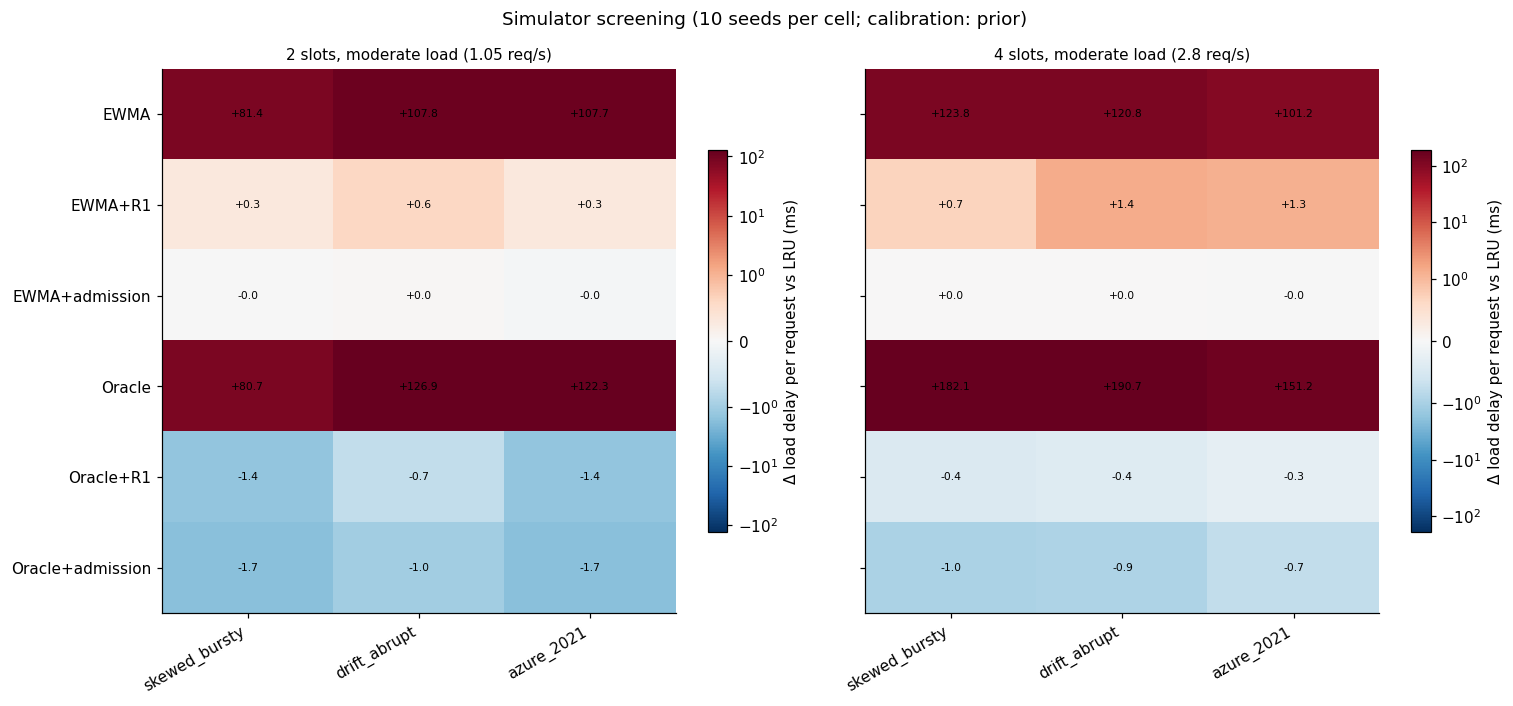

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5), sharey=True)
policies = [p for p in SIM_POLICIES if p != 'LRU']
scen = [s for s in ALL_SCENARIOS if s in set(SIM.scenario)]
for ax, slots in zip(axes, [2, 4]):
    mat = (SIM[(SIM.slots == slots) & (SIM.policy != 'LRU')]
           .groupby(['policy', 'scenario']).d_load_delay_ms_per_req.mean().unstack().reindex(index=policies, columns=scen))
    lim = max(1.0, np.nanmax(np.abs(mat.values)))
    im = ax.imshow(mat.values, cmap='RdBu_r', aspect='auto',
                   norm=matplotlib.colors.SymLogNorm(linthresh=1.0, vmin=-lim, vmax=lim))   # log beyond ±1 ms
    ax.set_xticks(range(len(scen)), scen, rotation=30, ha='right')
    ax.set_yticks(range(len(policies)), policies)
    ax.grid(False)
    for (r, c), v in np.ndenumerate(mat.values):
        ax.text(c, r, f'{v:+.1f}', ha='center', va='center', fontsize=7)
    ax.set_title(f'{slots} slots, moderate load ({level_rate(slots, "moderate")} req/s)', fontsize=10)
    fig.colorbar(im, ax=ax, shrink=0.7, label='Δ load delay per request vs LRU (ms)')
fig.suptitle(f'Simulator screening ({CONFIG["sim_seeds"]} seeds per cell; calibration: {calib(4)["source"]})')
fig.tight_layout()
savefig(fig, 'figS1_sim_policy_screen')

### 4.3 Simulator: how the answer depends on load
The cost rule predicts that prediction helps most at **light** load, when there is idle time, and least at heavy load. This sweep checks
that, with 4 slots and fractions of the capacity knee from 0.15 to 1.0, for the predictable scenarios and the uniform worst case.

saved figure: results/m3_20261103T011025Z/figures/figS2_sim_load_sweep.png


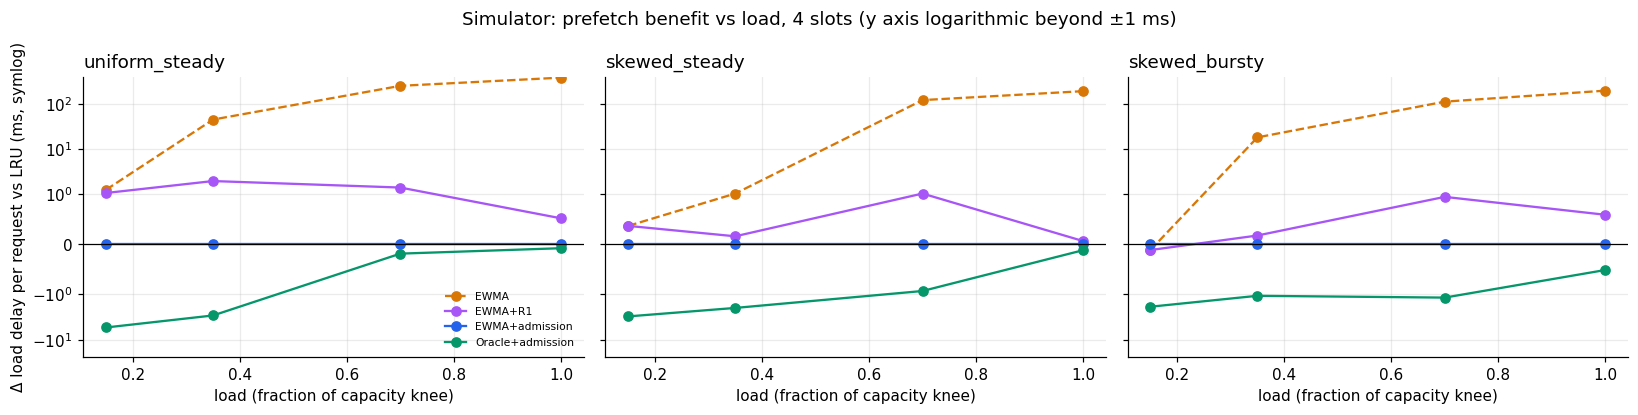

In [15]:
LOAD_FRACS = [0.15, 0.35, 0.7, 1.0]
LOAD_POLICIES = ['LRU', 'EWMA', 'EWMA+R1', 'EWMA+admission', 'Oracle+admission']
load_scen = [s for s in ['uniform_steady', 'skewed_steady', 'skewed_bursty'] if s in SCENARIO_SPECS]
rows = []
for frac in LOAD_FRACS:
    r = round(frac * calib(4)['knee_rate'], 3)
    rows.append(sim_grid(load_scen, LOAD_POLICIES, [4], range(max(4, CONFIG['sim_seeds'] // 2)), level=f'{frac:g}', rate=r))
SIM_LOAD = add_deltas(pd.concat(rows), ['scenario', 'slots', 'level', 'seed'], ['load_delay_ms_per_req'])
SIM_LOAD['frac'] = SIM_LOAD.level.astype(float)
SIM_LOAD.to_csv(RUN_DIR / 'sim_load_sweep.csv', index=False)
fig, axes = plt.subplots(1, len(load_scen), figsize=(5 * len(load_scen), 3.8), sharey=True, squeeze=False)
for ax, scen in zip(axes[0], load_scen):
    for pol in LOAD_POLICIES[1:]:
        g = SIM_LOAD[(SIM_LOAD.scenario == scen) & (SIM_LOAD.policy == pol)].groupby('frac').d_load_delay_ms_per_req.mean()
        ax.plot(g.index, g.values, marker='o', color=policy_color(pol), label=pol, ls='--' if pol == 'EWMA' else '-')
    ax.axhline(0, color='black', lw=0.8)
    ax.set_xlabel('load (fraction of capacity knee)')
    ax.set_title(scen, loc='left')
axes[0, 0].set_ylabel('Δ load delay per request vs LRU (ms, symlog)')
for ax in axes[0]:
    ax.set_yscale('symlog', linthresh=1.0)
axes[0, 0].legend(fontsize=7, frameon=False)
fig.suptitle('Simulator: prefetch benefit vs load, 4 slots (y axis logarithmic beyond ±1 ms)')
fig.tight_layout()
savefig(fig, 'figS2_sim_load_sweep')

### 4.4 Simulator: where is there headroom? (skew × temporal locality)
Steady arrivals, 4 slots, moderate load, varying popularity skew and locality. The left panel is the oracle's headroom and the right is how much
of it EWMA+admission captures. Expect headroom only at high skew and low locality. With high locality LRU already keeps the right
adapters; with no skew there is nothing to predict.

saved figure: results/m3_20261103T011025Z/figures/figS3_sim_skew_locality.png


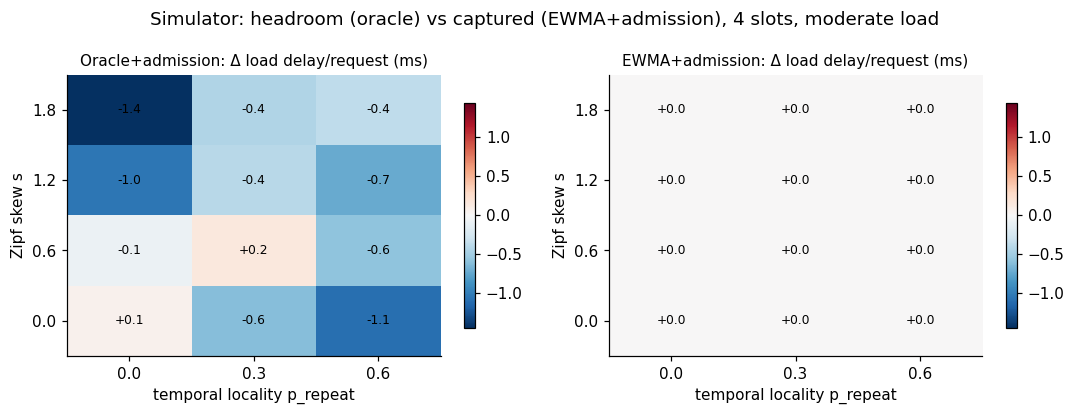

In [16]:
SKEWS, LOCALITIES = [0.0, 0.6, 1.2, 1.8], [0.0, 0.3, 0.6]
r = level_rate(4, 'moderate')
svc = service_s(4, r)
rows = []
for s in SKEWS:
    for pr in LOCALITIES:
        for seed in range(100, 100 + max(4, CONFIG['sim_seeds'] // 2)):
            tr = make_synthetic_trace('sweep', seed, r, zipf_s=s, locality=dict(p_repeat=pr, window=3) if pr else None)
            for pol in ['LRU', 'EWMA+admission', 'Oracle+admission']:
                rows.append({'zipf_s': s, 'p_repeat': pr, 'seed': seed, 'policy': pol,
                             **simulate(tr, make_policy(pol, 4), svc)})
SWEEP = add_deltas(pd.DataFrame(rows), ['zipf_s', 'p_repeat', 'seed'], ['load_delay_ms_per_req'])
SWEEP.to_csv(RUN_DIR / 'sim_sweep_skew_locality.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
mats = {pol: SWEEP[SWEEP.policy == pol].groupby(['zipf_s', 'p_repeat']).d_load_delay_ms_per_req.mean().unstack()
        for pol in ['Oracle+admission', 'EWMA+admission']}
lim = max(1.0, max(np.nanmax(np.abs(m.values)) for m in mats.values()))
for ax, (pol, mat) in zip(axes, mats.items()):
    im = ax.imshow(mat.values, cmap='RdBu_r', vmin=-lim, vmax=lim, origin='lower', aspect='auto')
    ax.set_xticks(range(len(LOCALITIES)), LOCALITIES)
    ax.set_yticks(range(len(SKEWS)), SKEWS)
    ax.set_xlabel('temporal locality p_repeat')
    ax.set_ylabel('Zipf skew s')
    ax.grid(False)
    ax.set_title(f'{pol}: Δ load delay/request (ms)', fontsize=10)
    for (i, j), v in np.ndenumerate(mat.values):
        ax.text(j, i, f'{v:+.1f}', ha='center', va='center', fontsize=8)
    fig.colorbar(im, ax=ax, shrink=0.8)
fig.suptitle('Simulator: headroom (oracle) vs captured (EWMA+admission), 4 slots, moderate load')
fig.tight_layout()
savefig(fig, 'figS3_sim_skew_locality')

---
# Part 5: GPU harness
### 5.1 How it works
```
 trace (arrival_s, adapter) ──► replay loop (this notebook, one thread)
                                 │  1. add requests whose arrival time has come   engine.add_request(...)
                                 │  2. every 0.25 s: policy.close_tick(); decide()  → engine.add_lora(c) = prefetch / touch
                                 │  3. one scheduler + GPU iteration               engine.step()
                                 ▼
                     vLLM 0.32 LLMEngine, in-process (VLLM_ENABLE_V1_MULTIPROCESSING=0)
                                 │  every step: set_active_adapters(batch) ─► activate_adapter() per adapter
                                 ▼
                     ResidencyProbe: wraps 3 methods, never changes a decision
                        • activate_adapter    → each GPU activation: demand/prefetch, LRU victim, timing, requests in flight
                        • set_active_adapters → adapters used by every step (to judge prefetches useful/wasted)
                        • _load_adapter       → any CPU/disk load (must be zero during measurements)
```
* **In-process engine.** The notebook calls `engine.step()` itself, so the probe is an ordinary Python object and the replay loop owns
  the clock. Milestone 1 wrote `.py` files only because its engine ran in a separate process. The trade-off: after a CUDA crash or OOM, use Runtime → Restart session.
* **TTFT** is measured from each request's *scheduled* arrival, so delays the loop causes count against the policy that caused them.
  **End-to-end** latency runs from scheduled arrival to the last token.
* **Prefetches run between steps**, where vLLM's own engine loop handles `add_lora`. Under load they delay everyone in flight. That is real, and it is measured.
* `async_scheduling=False`, so each activation falls inside one step and an out-of-band `add_lora` never races an in-flight batch.
  Production vLLM overlaps more.
* **Engine modes.** `eager` (milestones 1–2) launches every kernel from Python. `cuda_graphs` sets `enforce_eager=False`: vLLM
  compiles the model and captures CUDA graphs, including LoRA cases, at startup (a few extra minutes). Steps should get much faster
  while adapter activation (host-side copies) should not, so loads become *relatively* more expensive. Run the `quick` preset in both modes to compare.
* **dtype:** bfloat16 on GPUs that support it (compute capability ≥ 8: L4, A100, H100), else float16 (T4). The model is natively bf16,
  so this avoids milestone 2's flood of "casting" warnings.
* Every log entry gets a global **sequence number**, so prefetched → used → evicted is ordered exactly.

In [17]:
os.environ['VLLM_ENABLE_V1_MULTIPROCESSING'] = '0'   # engine core + GPU worker run inside this notebook process
os.environ['VLLM_NO_USAGE_STATS'] = '1'
os.environ.setdefault('VLLM_LOGGING_LEVEL', 'WARNING')
os.environ.setdefault('TOKENIZERS_PARALLELISM', 'false')

try:
    import torch
except ImportError:
    torch = None


def resolve_revision(model_id, revision):
    """Pin the Hugging Face model to an exact commit so reruns use identical weights."""
    try:
        from huggingface_hub import HfApi
        return HfApi().model_info(model_id, revision=revision).sha
    except Exception as exc:
        print('Could not resolve the model revision, using', revision, '|', exc)
        return revision


def pick_dtype():
    if torch is not None and torch.cuda.is_available() and torch.cuda.get_device_capability(0)[0] >= 8:
        return 'bfloat16'
    return 'half'


def projection_shapes(model_config):
    """(out, in) shapes of q_proj and v_proj for Qwen2, including grouped-query attention."""
    if model_config['model_type'] != 'qwen2':
        raise ValueError('The synthetic adapter builder supports Qwen2 models only.')
    hidden, heads = int(model_config['hidden_size']), int(model_config['num_attention_heads'])
    kv_heads = int(model_config.get('num_key_value_heads', heads))
    head_dim = int(model_config.get('head_dim') or hidden // heads)
    return {'q_proj': (heads * head_dim, hidden), 'v_proj': (kv_heads * head_dim, hidden)}


def make_synthetic_adapters(model_config, revision, out_dir):
    """Untrained but non-zero rank-r PEFT adapters. They exercise loading and LoRA kernels exactly like trained
    adapters of the same shape; their output text is meaningless. Regenerated identically from the seed."""
    from safetensors.numpy import save_file
    shapes = projection_shapes(model_config.to_dict())
    manifest = []
    for adapter_id in ADAPTER_IDS:
        dest = out_dir / f'adapter_{adapter_id}'
        dest.mkdir(parents=True, exist_ok=True)
        rng = np.random.default_rng(CONFIG['seed'] + adapter_id)
        weights = {}
        for layer in range(model_config.num_hidden_layers):
            for name, (out_dim, in_dim) in shapes.items():
                prefix = f'base_model.model.model.layers.{layer}.self_attn.{name}'
                weights[f'{prefix}.lora_A.weight'] = rng.normal(0, 0.01, (CONFIG['rank'], in_dim)).astype(np.float16)
                weights[f'{prefix}.lora_B.weight'] = rng.normal(0, 0.001, (out_dim, CONFIG['rank'])).astype(np.float16)
        (dest / 'adapter_config.json').write_text(json.dumps({
            'base_model_name_or_path': CONFIG['model_id'], 'revision': revision, 'peft_type': 'LORA',
            'task_type': 'CAUSAL_LM', 'r': CONFIG['rank'], 'lora_alpha': 2 * CONFIG['rank'], 'lora_dropout': 0.0,
            'bias': 'none', 'inference_mode': True, 'target_modules': list(shapes), 'fan_in_fan_out': False}, indent=2))
        save_file(weights, str(dest / 'adapter_model.safetensors'))
        manifest.append({'adapter_id': adapter_id, 'path': str(dest), 'synthetic_untrained': True,
                         'payload_bytes': int(sum(w.nbytes for w in weights.values()))})
    return manifest

### 5.2 Residency probe
The same probe as milestone 2. It wraps three methods on the live objects and always calls vLLM's original, so LRU still makes every
eviction decision. New: each activation also records **how many requests were in flight**, which the load-delay metric needs.
`host_ms` is wall time around an activation. `cuda_ms` (when available) is a CUDA-event interval on the current stream.
Neither is pure PCIe time; the 2.2 MB transfer itself takes ~0.1 ms.

In [18]:
class ResidencyProbe:
    """Observe vLLM's GPU LoRA slot cache without changing its decisions (vLLM 0.32, in-process engine)."""

    def __init__(self, engine, payload_bytes):
        self.worker_mgr = self._find_worker_manager(engine)
        self.mgr = self.worker_mgr._adapter_manager
        for attr in ('activate_adapter', 'deactivate_adapter', 'lora_index_to_id', '_active_adapters', 'list_adapters'):
            if not hasattr(self.mgr, attr):
                raise RuntimeError(f'Unexpected vLLM LoRA manager layout (missing {attr}). Use vLLM {VLLM_VERSION}.')
        if not hasattr(self.mgr._active_adapters, 'order'):
            raise RuntimeError('LRU order is not readable; this probe needs vLLM 0.32-style LRUCache.order.')
        self.payload_bytes = payload_bytes
        self.context = {'run': 'setup', 'source': 'setup', 'step': -1, 'inflight': 0}
        self.activations, self.steps, self.loads = [], [], []
        self._seq = 0
        self.t0 = time.perf_counter()
        self.use_cuda_events = torch is not None and torch.cuda.is_available()
        self._install()

    @staticmethod
    def _find_worker_manager(engine):
        worker = getattr(getattr(getattr(engine, 'model_executor', None), 'driver_worker', None), 'worker', None)
        manager = getattr(getattr(worker, 'model_runner', None), 'lora_manager', None)
        if manager is None:
            manager = engine.collective_rpc(lambda w: w.model_runner.lora_manager)[0]
        return manager

    def next_seq(self):
        self._seq += 1
        return self._seq

    def lru_order(self):
        """Resident adapter ids, least recently used first (element 0 is the next LRU victim)."""
        return [int(a) for a in self.mgr._active_adapters.order]

    def gpu_slots(self):
        return [None if a is None else int(a) for a in self.mgr.lora_index_to_id]

    def cpu_registered(self):
        return sorted(int(a) for a in self.mgr.list_adapters())

    def _install(self):
        probe, mgr, wm = self, self.mgr, self.worker_mgr
        original_activate, original_set_active, original_load = mgr.activate_adapter, wm.set_active_adapters, wm._load_adapter

        def activate_adapter(lora_id):
            before = probe.lru_order()
            if lora_id in before:                 # already resident: vLLM only refreshes LRU order (a "touch")
                return original_activate(lora_id)
            events = None
            if probe.use_cuda_events:
                events = (torch.cuda.Event(enable_timing=True), torch.cuda.Event(enable_timing=True))
                events[0].record()
            start = time.perf_counter()
            result = original_activate(lora_id)   # vLLM's own LRU eviction + copy into the slot
            end = time.perf_counter()
            if events:
                events[1].record()
            after = probe.lru_order()
            probe.activations.append({**probe.context, 'seq': probe.next_seq(), 't_s': start - probe.t0,
                                      'adapter_id': int(lora_id), 'host_ms': 1e3 * (end - start),
                                      'gpu_before': before, 'gpu_after': after,
                                      'evicted': [a for a in before if a not in after],
                                      'payload_bytes': probe.payload_bytes.get(int(lora_id)), '_cuda': events})
            return result

        def set_active_adapters(requests, mapping):
            probe.steps.append({'run': probe.context['run'], 'step': probe.context['step'], 'seq': probe.next_seq(),
                                't_s': time.perf_counter() - probe.t0,
                                'adapters': sorted({int(r.lora_int_id) for r in requests if r})})
            return original_set_active(requests, mapping)

        def load_adapter(lora_request):
            start = time.perf_counter()
            result = original_load(lora_request)
            probe.loads.append({**probe.context, 'seq': probe.next_seq(), 'adapter_id': int(lora_request.lora_int_id),
                                'ms': 1e3 * (time.perf_counter() - start)})
            return result

        mgr.activate_adapter = activate_adapter          # instance attributes: only this engine is affected
        wm.set_active_adapters = set_active_adapters
        wm._load_adapter = load_adapter

    def reset_gpu(self):
        """Empty every GPU slot; CPU copies stay. Only call when no request is in flight."""
        if self.use_cuda_events:
            torch.cuda.synchronize()
        for a in self.lru_order():
            self.mgr.deactivate_adapter(a)
        self.mgr._last_mapping = None
        if hasattr(self.mgr, '_last_slot_layout'):
            self.mgr._last_slot_layout = None
        if self.lru_order() or any(s is not None for s in self.gpu_slots()):
            raise RuntimeError(f'GPU slot reset failed: {self.gpu_slots()}')

    def take(self, run):
        """Remove and return (activations, steps, loads) for `run`; resolves CUDA timings (needs a sync)."""
        if self.use_cuda_events:
            torch.cuda.synchronize()
        out = []
        for name in ('activations', 'steps', 'loads'):
            log = getattr(self, name)
            mine = [e for e in log if e.get('run') == run]
            setattr(self, name, [e for e in log if e.get('run') != run])
            for e in mine:
                ev = e.pop('_cuda', None)
                if ev is not None:
                    e['cuda_ms'] = ev[0].elapsed_time(ev[1])
            out.append(mine)
        return tuple(out)

### 5.3 Engine wrapper
`ServingLab(n_slots)` creates one engine in the configured mode, attaches the probe, loads all 8 adapters into the CPU cache, clears the GPU
slots, and warms up with 3 rounds of every adapter. Changing the slot count needs a new engine, because `max_loras` is fixed at startup.
`shutdown()` releases it; milestone 2 confirmed memory is returned (21.7 of 22 GiB free afterwards).

In [19]:
class ServingLab:
    """One vLLM engine with `n_slots` GPU LoRA slots, all adapters in CPU memory, and a ResidencyProbe."""

    def __init__(self, n_slots):
        from vllm import EngineArgs, LLMEngine, SamplingParams
        from vllm.lora.request import LoRARequest
        from vllm.sampling_params import RequestOutputKind
        self.n_slots = n_slots
        args = EngineArgs(
            model=CONFIG['model_id'], revision=MODEL_REVISION, tokenizer_revision=MODEL_REVISION,
            dtype=DTYPE, seed=CONFIG['seed'], max_model_len=CONFIG['max_model_len'],
            max_num_seqs=CONFIG['max_num_seqs'], max_num_batched_tokens=CONFIG['max_num_batched_tokens'],
            gpu_memory_utilization=CONFIG['gpu_memory_utilization'], enforce_eager=(ENGINE_MODE == 'eager'),
            enable_prefix_caching=False, enable_lora=True, max_loras=n_slots,
            max_cpu_loras=CONFIG['n_adapters'], max_lora_rank=CONFIG['rank'], lora_dtype='auto',
            distributed_executor_backend='uni', async_scheduling=False, disable_log_stats=True)
        self.engine_args = {k: (v if isinstance(v, (int, float, str, bool, type(None))) else str(v))
                            for k, v in vars(args).items()}
        start = time.perf_counter()
        self.engine = LLMEngine.from_engine_args(args)
        self.startup_s = time.perf_counter() - start
        self.lora = {m['adapter_id']: LoRARequest(f"adapter_{m['adapter_id']}", m['adapter_id'], m['path'])
                     for m in ADAPTER_MANIFEST}
        self.params = SamplingParams(temperature=0.0, max_tokens=CONFIG['output_tokens'], ignore_eos=True,
                                     output_kind=RequestOutputKind.DELTA)
        self.probe = ResidencyProbe(self.engine, {m['adapter_id']: m['payload_bytes'] for m in ADAPTER_MANIFEST})
        self.probe.context.update(run='setup', source='cpu_preload')
        for request in self.lora.values():
            self.engine.add_lora(request)
        if self.probe.cpu_registered() != ADAPTER_IDS:
            raise RuntimeError(f'CPU cache holds {self.probe.cpu_registered()}, expected {ADAPTER_IDS}')
        self.probe.reset_gpu()
        self.warm_up()
        print(f'Engine ({ENGINE_MODE}, {DTYPE}) with {n_slots} GPU slots ready in {self.startup_s:.0f} s; '
              f'CPU cache {self.probe.cpu_registered()}, GPU slots {self.probe.gpu_slots()}')

    def add(self, request_id, adapter_id):
        self.engine.add_request(request_id, {'prompt_token_ids': list(PROMPT_TOKENS)}, self.params,
                                lora_request=self.lora[adapter_id])

    def prefetch(self, adapter_id):
        """vLLM's public API. For a CPU-cached adapter this activates it on the GPU (LRU picks the victim)."""
        return self.engine.add_lora(self.lora[adapter_id])

    def drain(self):
        while self.engine.has_unfinished_requests():
            self.engine.step()

    def warm_up(self):
        self.probe.context.update(run='warmup', source='demand')
        for round_ in range(3):
            for a in ADAPTER_IDS:
                self.add(f'warmup-{round_}-{a}', a)
            self.drain()
        self.probe.take('warmup')
        self.probe.reset_gpu()

    def shutdown(self):
        try:
            self.engine.engine_core.shutdown()
        except Exception as exc:
            print('engine shutdown warning:', exc)
        self.engine = self.probe = None
        gc.collect()
        try:
            from vllm.distributed.parallel_state import cleanup_dist_env_and_memory
            cleanup_dist_env_and_memory()
        except Exception as exc:
            print('distributed cleanup warning:', exc)
        if torch is not None and torch.cuda.is_available():
            torch.cuda.empty_cache()
            free, total = torch.cuda.mem_get_info()
            print(f'Engine released; GPU free memory {free / 2**30:.1f} / {total / 2**30:.1f} GiB')

### 5.4 Replay loop and per-run summary
`replay()` is the core of the GPU experiment (same structure as milestone 2, with comments for each step). `summarize_run()` joins request
rows with the probe logs:
* **Demand load**: an activation inside `engine.step()`. **Prefetch useful/wasted**: did a step use the adapter between the prefetch and its next eviction?
* **Prefetch-induced load**: a demand load within 2 s of a prefetch evicting that adapter.
* **Load delay per request**: Σ (host ms × requests in flight) ÷ requests. **Stall share**: the fraction of the run spent inside activations.
* **Latency**: TTFT mean/p50/p95/p99 and end-to-end mean/p95, all from scheduled arrival.

In [20]:
def replay(lab, trace, policy, run):
    """Replay one trace under one policy. Returns (requests, decisions, step_ms, run start offset in probe time)."""
    eng, probe, cfg = lab.engine, lab.probe, CONFIG
    if eng.has_unfinished_requests():
        raise RuntimeError('Engine still has unfinished requests from a previous run.')
    probe.reset_gpu()                   # every run starts from the same state: empty GPU, all adapters in CPU memory
    policy.reset(trace)                 # the oracle receives the trace; the other predictors ignore it
    probe.context.update(run=run, source='demand', step=0, inflight=0)
    arrivals = list(zip(trace['arrival_s'].to_numpy(float), trace['adapter_id'].to_numpy(int)))
    n, i, step = len(arrivals), 0, 0
    rows, inflight, decisions, step_ms = {}, {}, [], []
    tick, next_tick = cfg['tick_s'], cfg['tick_s']
    guard_s = float(trace['arrival_s'].max() if n else 0) + 180.0
    t0 = time.perf_counter()

    def clock():
        return time.perf_counter() - t0

    def admit(until):
        """Submit every request whose scheduled arrival is ≤ `until`; the predictor sees it only now."""
        nonlocal i
        while i < n and arrivals[i][0] <= until:
            t_sched, a = arrivals[i]
            rid = f'{run}#{i}'
            rows[rid] = {'run': run, 'req': i, 'adapter_id': int(a), 'arrival_s': t_sched, 'added_s': clock(),
                         'resident_at_arrival': int(a) in probe.lru_order(), 'add_seq': probe.next_seq(),
                         'first_token_s': np.nan, 'first_seq': np.nan, 'finish_s': np.nan, 'tokens': 0}
            lab.add(rid, int(a))
            inflight[rid] = int(a)
            policy.observe(int(a), t_sched)
            i += 1

    while True:
        now = clock()
        # 1) Predictor ticks, in time order. A tick sees only arrivals strictly before it.
        if next_tick <= now:
            while next_tick <= now:
                admit(next_tick - 1e-9)
                policy.close_tick(next_tick)
                decided_at, next_tick = next_tick, next_tick + tick
            view = {'resident_lru': probe.lru_order(), 'busy': set(inflight.values()), 'inflight': len(inflight)}
            for d in policy.decide(decided_at, view):
                d.update(run=run, wall_s=clock(), step=step, control_ms=0.0)
                if d['action'] == 'prefetch':
                    s = time.perf_counter()
                    probe.context.update(source='touch', inflight=len(inflight))
                    for a in d['touches']:
                        lab.prefetch(a)
                    probe.context['source'] = 'prefetch'
                    lab.prefetch(d['candidate'])
                    probe.context['source'] = 'demand'
                    d['control_ms'] = 1e3 * (time.perf_counter() - s)
                    d['gpu_after'] = probe.lru_order()
                decisions.append(d)
        # 2) Arrivals that are due now.
        admit(clock())
        # 3) One engine iteration if there is work; otherwise sleep until the next arrival or tick.
        if eng.has_unfinished_requests():
            probe.context.update(step=step, inflight=len(inflight))
            s = time.perf_counter()
            outputs = eng.step()
            e = time.perf_counter()
            step_ms.append(1e3 * (e - s))
            step += 1
            for out in outputs:
                row = rows.get(out.request_id)
                if row is None:
                    continue
                new_tokens = sum(len(c.token_ids) for c in out.outputs)
                if new_tokens and np.isnan(row['first_token_s']):
                    row['first_token_s'], row['first_seq'] = e - t0, probe.next_seq()
                row['tokens'] += new_tokens
                if out.finished:
                    row['finish_s'] = e - t0
                    inflight.pop(out.request_id, None)
        elif i >= n:
            break
        else:
            time.sleep(max(0.0, min(arrivals[i][0], next_tick) - clock()))
        if clock() > guard_s:
            raise RuntimeError(f'{run}: replay exceeded {guard_s:.0f} s; the engine is overloaded or stuck.')

    req = pd.DataFrame(list(rows.values()))
    if len(req):
        req['ttft_ms'] = 1e3 * (req.first_token_s - req.arrival_s)
        req['queue_lag_ms'] = 1e3 * (req.added_s - req.arrival_s)
        req['e2e_ms'] = 1e3 * (req.finish_s - req.arrival_s)
    return req, decisions, step_ms, t0 - probe.t0


def summarize_run(req, decisions, step_ms, acts, steps, loads, meta, t_offset=0.0):
    """Join request rows with probe logs; return (summary dict, enriched requests, activation rows)."""
    H = CONFIG['horizon_s']
    for e in acts:
        e['run_t_s'] = e['t_s'] - t_offset
    evictions = defaultdict(list)                 # adapter -> [(seq, cause, time)]
    for e in acts:
        for v in e['evicted']:
            evictions[v].append((e['seq'], e['source'], e['t_s']))
    uses = defaultdict(list)
    for s in steps:
        for a in s['adapters']:
            uses[a].append(s['seq'])
    useful = wasted = induced = 0
    for e in acts:
        a = e['adapter_id']
        if e['source'] == 'prefetch':
            end = min([seq for seq, _, _ in evictions[a] if seq > e['seq']], default=math.inf)
            e['prefetch_outcome'] = 'useful' if any(e['seq'] < u < end for u in uses[a]) else 'wasted'
            useful += e['prefetch_outcome'] == 'useful'
            wasted += e['prefetch_outcome'] == 'wasted'
        if e['source'] == 'demand':
            prior = [ev for ev in evictions[a] if ev[0] < e['seq']]
            last = max(prior) if prior else None
            e['induced_by_prefetch'] = bool(last and last[1] == 'prefetch' and e['t_s'] - last[2] <= H)
            induced += e['induced_by_prefetch']
    demand = [e for e in acts if e['source'] == 'demand']
    prefetch_acts = [e for e in acts if e['source'] == 'prefetch']
    demand_by_adapter = defaultdict(list)
    for e in demand:
        demand_by_adapter[e['adapter_id']].append(e['seq'])
    req = req.copy()
    req['waited_for_load'] = [any(r.add_seq < s < r.first_seq for s in demand_by_adapter[r.adapter_id])
                              for r in req.itertuples()]
    payload = {m['adapter_id']: m['payload_bytes'] for m in ADAPTER_MANIFEST}
    reasons = Counter(d['reason'] for d in decisions if d['action'] == 'skip')
    ttft, e2e = req['ttft_ms'].dropna(), req['e2e_ms'].dropna()
    nreq = max(len(req), 1)
    run_s = float(req['finish_s'].max()) if len(req) else float('nan')
    stall_ms = sum(e['host_ms'] for e in acts)
    summary = {
        **meta,
        'requests': len(req), 'completed': int(req['finish_s'].notna().sum()),
        'tokens_ok': bool((req['tokens'] == CONFIG['output_tokens']).all()),
        'ttft_mean_ms': ttft.mean(), 'ttft_p50_ms': ttft.quantile(0.50), 'ttft_p95_ms': ttft.quantile(0.95),
        'ttft_p99_ms': ttft.quantile(0.99), 'e2e_mean_ms': e2e.mean(), 'e2e_p95_ms': e2e.quantile(0.95),
        'queue_lag_p95_ms': req['queue_lag_ms'].quantile(0.95),
        'hit_at_arrival': req['resident_at_arrival'].mean(), 'waited_for_load_frac': req['waited_for_load'].mean(),
        'demand_loads': len(demand), 'prefetch_loads': len(prefetch_acts),
        'useful_prefetches': useful, 'wasted_prefetches': wasted,
        'wasted_MB': sum(payload[e['adapter_id']] for e in prefetch_acts if e.get('prefetch_outcome') == 'wasted') / 1e6,
        'prefetch_induced_loads': induced,
        'demand_per100': 100 * len(demand) / nreq, 'prefetch_per100': 100 * len(prefetch_acts) / nreq,
        'induced_per100': 100 * induced / nreq, 'wasted_per100': 100 * wasted / nreq, 'useful_per100': 100 * useful / nreq,
        'load_delay_ms_per_req': sum(e['host_ms'] * e.get('inflight', 0) for e in acts) / nreq,
        'stall_share': (stall_ms / 1e3) / run_s if run_s > 0 else np.nan,
        'activation_ms_median': float(np.median([e['host_ms'] for e in acts])) if acts else np.nan,
        'evictions': sum(len(e['evicted']) for e in acts),
        'max_resident': max([len(e['gpu_after']) for e in acts], default=0),
        'cpu_reloads': len(loads),
        'steps': len(step_ms), 'step_ms_mean': float(np.mean(step_ms)) if step_ms else np.nan,
        'prefetch_control_ms_total': float(sum(d.get('control_ms', 0.0) for d in decisions)),
        'decisions': len(decisions), **{f'skip_{k}': v for k, v in reasons.items()},
        'run_wall_s': run_s,
    }
    return summary, req, acts

### 5.5 Build adapters, tokenize the prompt, start the first engine
The base model (~3 GB) is downloaded on the first run. Every request uses the same prompt of exactly `prompt_tokens` token IDs.
Prefix caching is off, so each still does a full prefill. EOS is ignored, so each produces exactly `output_tokens` tokens.

In [21]:
LAB_ENGINE = None
if HAS_GPU:
    from transformers import AutoConfig, AutoTokenizer
    MODEL_REVISION = resolve_revision(CONFIG['model_id'], CONFIG['revision'])
    DTYPE = pick_dtype()
    model_config = AutoConfig.from_pretrained(CONFIG['model_id'], revision=MODEL_REVISION)
    tokenizer = AutoTokenizer.from_pretrained(CONFIG['model_id'], revision=MODEL_REVISION)
    ADAPTER_MANIFEST = make_synthetic_adapters(model_config, MODEL_REVISION, RUN_DIR / 'adapters')
    base = tokenizer.encode('Explain how a computer cache stores frequently used information. ', add_special_tokens=False)
    PROMPT_TOKENS = (base * (CONFIG['prompt_tokens'] // len(base) + 1))[:CONFIG['prompt_tokens']]
    print('Model revision:', MODEL_REVISION, '| dtype:', DTYPE, '| engine mode:', ENGINE_MODE)
    print(f"{len(ADAPTER_MANIFEST)} synthetic adapters, {ADAPTER_MANIFEST[0]['payload_bytes'] / 1e6:.2f} MB each")
    LAB_ENGINE = ServingLab(SLOT_CONFIGS[-1])
    ENVIRONMENT = {
        'started_utc': datetime.now(timezone.utc).isoformat(), 'python': sys.version, 'gpu': GPU_SUMMARY,
        'torch': torch.__version__ if torch else None, 'torch_cuda': torch.version.cuda if torch else None,
        'vllm': installed_version('vllm'), 'transformers': installed_version('transformers'),
        'model_revision': MODEL_REVISION, 'dtype': DTYPE, 'engine_mode': ENGINE_MODE,
        'engine_args_first_engine': LAB_ENGINE.engine_args, 'adapter_manifest': ADAPTER_MANIFEST,
    }
    (RUN_DIR / 'environment.json').write_text(json.dumps(ENVIRONMENT, indent=2, default=str))
    (RUN_DIR / 'pip_freeze.txt').write_text(subprocess.run([sys.executable, '-m', 'pip', 'freeze'],
                                                          text=True, capture_output=True).stdout)
else:
    print('No GPU: skipping engine start.')

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


Model revision: 989aa7980e4cf806f80c7fef2b1adb7bc71aa306 | dtype: bfloat16 | engine mode: eager
8 synthetic adapters, 2.18 MB each
(MainProcess pid=3664) WARNING 11-03 01:13:53 [arg_utils.py:1945] The global random seed is set to 7. Since VLLM_ENABLE_V1_MULTIPROCESSING is set to False, this may affect the random state of the Python process that launched vLLM.
(MainProcess pid=3664) WARNING 11-03 01:14:10 [vllm.py:1703] Enforce eager set, disabling torch.compile, CUDAGraphs, and JIT kernel warmup. This is equivalent to setting -cc.mode=none -cc.cudagraph_mode=none and --kernel_config.enable_jit_warmup=False
(MainProcess pid=3664) WARNING 11-03 01:14:10 [vllm.py:1727] Inductor compilation was disabled by user settings, optimizations settings that are only active during inductor compilation will be ignored.


Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]


(MainProcess pid=3664) WARNING 11-03 01:14:33 [utils.py:276] Using default LoRA kernel configs
(MainProcess pid=3664) WARNING 11-03 01:14:40 [input_processor.py:289] vLLM has deprecated support for supporting different tokenizers for different LoRAs. By default, vLLM uses base model's tokenizer. If you are using a LoRA with its own tokenizer, consider specifying `--tokenizer [lora_path]` to use the LoRA tokenizer.
(MainProcess pid=3664) WARNING 11-03 01:14:40 [input_processor.py:408] Passing raw prompts to InputProcessor is deprecated and will be removed in the future. You should instead pass the outputs of Renderer.render_cmpl() or Renderer.render_chat().
Engine (eager, bfloat16) with 4 GPU slots ready in 47 s; CPU cache [1, 2, 3, 4, 5, 6, 7, 8], GPU slots [None, None, None, None]


### 5.6 Milestone-1 replication, generalised to any slot count
This is the same paired experiment as milestones 1 and 2, now runnable with S slots. Prime adapters `1…S` then `1…S−1`, so the LRU victim is S. Then:
* **Forced sequence**: request S+1 must evict S, and a second request for S+1 must be a hit.
* **Paired trials**, with arm order randomised. After the same idle gap, the **demand** arm requests S+1 cold. The **prefetch** arm calls
  `add_lora(S+1)` 50 ms into the gap, so S+1 is resident when its request arrives.

The median TTFT difference is the user-visible cost of one load in the best case. It is reported next to the **decode step time**,
because the ratio (load ÷ step) is what decides how much caching can matter at all.

In [22]:
DIAG_FILE, DIAG_CHECK_FILE = RUN_DIR / 'diagnostic_pairs.csv', RUN_DIR / 'diagnostic_checks.csv'


def single_request(lab, adapter_id, run, scheduled=None):
    """Submit one request (optionally at a scheduled time), step to completion, return its timings."""
    probe = lab.probe
    if scheduled is not None:
        time.sleep(max(0.0, scheduled - time.perf_counter()))
    resident = adapter_id in probe.lru_order()
    probe.context.update(run=run, source='demand', inflight=1)
    rid = f'{run}#{probe.next_seq()}'
    start = time.perf_counter()
    lab.add(rid, adapter_id)
    first, tokens, steps = None, 0, []
    while lab.engine.has_unfinished_requests():
        s = time.perf_counter()
        outputs = lab.engine.step()
        steps.append(1e3 * (time.perf_counter() - s))
        for out in outputs:
            n_new = sum(len(c.token_ids) for c in out.outputs)
            if out.request_id == rid and n_new and first is None:
                first = time.perf_counter()
            tokens += n_new if out.request_id == rid else 0
    if first is None or tokens != CONFIG['output_tokens']:
        raise RuntimeError(f'{run}: expected {CONFIG["output_tokens"]} tokens, got {tokens}')
    return {'adapter_id': adapter_id, 'resident_before': resident, 'ttft_ms': 1e3 * (first - start),
            'decode_step_ms': float(np.median(steps[1:])) if len(steps) > 1 else np.nan, 'gpu_after': probe.lru_order()}


def milestone1_diagnostic(lab):
    probe, cfg, S = lab.probe, CONFIG, lab.n_slots
    prime, victim, target = list(range(1, S + 1)) + list(range(1, S)), S, S + 1
    checks = []
    probe.reset_gpu()
    rows = [single_request(lab, a, f'diag{S}_forced') for a in prime + [target, target]]
    acts, _, _ = probe.take(f'diag{S}_forced')
    checks.append({'slots': S, 'check': f'forced sequence evicts adapter {victim} (the LRU)',
                   'passed': any(e['adapter_id'] == target and e['evicted'] == [victim] for e in acts)})
    checks.append({'slots': S, 'check': 'forced sequence: repeat request is a GPU hit', 'passed': rows[-1]['resident_before']})
    rng = random.Random(cfg['seed'])
    out = []
    for trial in range(cfg['diag_repeats']):
        arms = ['demand', 'prefetch']
        rng.shuffle(arms)
        for arm in arms:
            run = f'diag{S}_{trial}_{arm}'
            probe.reset_gpu()
            for a in prime:
                single_request(lab, a, run)
            if probe.lru_order() != [victim] + list(range(1, S)):
                raise RuntimeError(f'Priming produced LRU order {probe.lru_order()}')
            gap_start = time.perf_counter()
            prefetch_ms = np.nan
            if arm == 'prefetch':
                time.sleep(max(0.0, gap_start + cfg['diag_prefetch_offset_s'] - time.perf_counter()))
                probe.context.update(run=run, source='prefetch', inflight=0)
                s = time.perf_counter()
                lab.prefetch(target)
                prefetch_ms = 1e3 * (time.perf_counter() - s)
                if probe.lru_order() != list(range(1, S)) + [target]:
                    raise RuntimeError(f'Prefetch produced {probe.lru_order()}')
            row = single_request(lab, target, run, scheduled=gap_start + cfg['diag_gap_s'])
            acts, _, loads = probe.take(run)
            if row['resident_before'] != (arm == 'prefetch'):
                raise RuntimeError(f'{run}: target residency differs from the intended arm')
            act = [e for e in acts if e['adapter_id'] == target]
            out.append({'slots': S, 'gpu': GPU_NAME, 'engine_mode': ENGINE_MODE, 'trial': trial, 'arm': arm,
                        'ttft_ms': row['ttft_ms'], 'decode_step_ms': row['decode_step_ms'],
                        'prefetch_control_ms': prefetch_ms,
                        'activation_host_ms': act[0]['host_ms'] if act else np.nan, 'cpu_reloads': len(loads)})
    diag = pd.DataFrame(out)
    checks.append({'slots': S, 'check': 'diagnostic: no CPU/disk reloads', 'passed': int(diag.cpu_reloads.sum()) == 0})
    return diag, checks


def run_diagnostic_if_needed(lab):
    done = pd.read_csv(DIAG_FILE) if DIAG_FILE.exists() else pd.DataFrame(columns=['slots'])
    if lab.n_slots in set(done['slots']):
        print(f'Diagnostic for {lab.n_slots} slots already in this run folder; skipping.')
        return
    diag, checks = milestone1_diagnostic(lab)
    pd.concat([done, diag], ignore_index=True).to_csv(DIAG_FILE, index=False)
    old = pd.read_csv(DIAG_CHECK_FILE) if DIAG_CHECK_FILE.exists() else pd.DataFrame()
    pd.concat([old, pd.DataFrame(checks)], ignore_index=True).to_csv(DIAG_CHECK_FILE, index=False)
    p = diag.pivot(index='trial', columns='arm', values='ttft_ms')
    saving = (p['demand'] - p['prefetch']).median()
    step = diag.decode_step_ms.median()
    print(f"Diagnostic ({lab.n_slots} slots): TTFT demand {p['demand'].median():.1f} ms vs prefetch {p['prefetch'].median():.1f} ms "
          f"→ one load costs {saving:.2f} ms; decode step {step:.1f} ms (load = {saving / step:.0%} of a step); "
          f"checks {'all passed' if all(c['passed'] for c in checks) else 'FAILED'}")


if LAB_ENGINE is not None:
    run_diagnostic_if_needed(LAB_ENGINE)

Diagnostic (4 slots): TTFT demand 81.7 ms vs prefetch 74.7 ms → one load costs 7.21 ms; decode step 71.1 ms (load = 10% of a step); checks all passed


---
# Part 6: Calibrate, then run the plan
### 6.1 Capacity calibration
For each slot count, before any experiment:
1. **Unloaded TTFT**: 5 single requests on a resident adapter, which is the best the engine can do.
2. **Rate probe**: replay uniform-popularity traffic under LRU at increasing rates (`probe_rates`, 20 s each). Stop once median TTFT exceeds 4× unloaded.
3. **Knee** = the highest probed rate with median TTFT ≤ 2 × unloaded. Load levels are 0.35/0.7/1.0 × knee.
4. The step time at each probed rate feeds the simulator's service time.

Uniform popularity is the hardest case for LRU, so the knee is conservative. If the knee is the highest probed rate, capacity is
above the probed range; add higher rates. If no rate passes, the lowest is used and a warning is printed.

### 6.2 The experiment loop
For each slot count: start the engine (reusing the current one when possible), run the diagnostic and calibration if they are not already in the
run folder, then replay every planned (block, level, scenario, seed) under every policy. The policy order is randomised within each group,
so slow GPU drift can't favour one policy. Completed runs are skipped when resuming.

In [ ]:
RESULT_KEYS = ('runs', 'requests', 'decisions', 'activations', 'calibration_probe')
RESULT_FILES = {k: RUN_DIR / f'{k}.csv' for k in RESULT_KEYS}
RESULTS = defaultdict(list)
for k, path in RESULT_FILES.items():           # resume: reload what is already on disk
    if path.exists():
        RESULTS[k] = pd.read_csv(path).to_dict('records')
DONE = {r['run'] for r in RESULTS['runs']}


def _jsonable(v):
    if isinstance(v, set):
        v = sorted(v)
    return json.dumps(v) if isinstance(v, (list, tuple, dict)) else v


def record(key, rows):
    """Add rows to RESULTS[key] and rewrite that CSV in full (columns can differ between runs)."""
    rows = rows.to_dict('records') if isinstance(rows, pd.DataFrame) else list(rows)
    RESULTS[key].extend({k: _jsonable(v) for k, v in r.items()} for r in rows)
    pd.DataFrame(RESULTS[key]).to_csv(RESULT_FILES[key], index=False)


def calibrate(lab):
    S, cfg = lab.n_slots, CONFIG
    lab.probe.reset_gpu()
    single_request(lab, 1, f'cal{S}_warm')
    singles = [single_request(lab, 1, f'cal{S}_unloaded') for _ in range(5)]
    lab.probe.take(f'cal{S}_warm')
    lab.probe.take(f'cal{S}_unloaded')
    unloaded = float(np.median([r['ttft_ms'] for r in singles]))
    decode = float(np.median([r['decode_step_ms'] for r in singles]))
    rows = []
    for rate in cfg['probe_rates']:
        run = f'probe|{S}|{rate}'
        tr = make_synthetic_trace('probe', 4242, rate, duration_s=cfg['probe_duration_s'], zipf_s=0.0)
        req, decisions, step_ms, off = replay(lab, tr, make_policy('LRU', S), run)
        acts, steps, loads = lab.probe.take(run)
        s, _, _ = summarize_run(req, decisions, step_ms, acts, steps, loads, {}, off)
        rows.append({'slots': S, 'gpu': GPU_NAME, 'engine_mode': ENGINE_MODE, 'rate': rate, 'requests': s['requests'],
                     'ttft_p50_ms': s['ttft_p50_ms'], 'ttft_p95_ms': s['ttft_p95_ms'], 'step_ms_mean': s['step_ms_mean'],
                     'activation_ms_median': s['activation_ms_median'], 'demand_per100': s['demand_per100'],
                     'unloaded_ttft_ms': unloaded})
        print(f"  probe {S} slots @ {rate:>4} req/s: TTFT p50 {s['ttft_p50_ms']:7.0f} ms, p95 {s['ttft_p95_ms']:7.0f} ms, "
              f"step {s['step_ms_mean']:5.1f} ms")
        if s['ttft_p50_ms'] > 4 * unloaded:
            break
    ok = [r['rate'] for r in rows if r['ttft_p50_ms'] <= cfg['knee_ttft_factor'] * unloaded]
    knee = max(ok) if ok else cfg['probe_rates'][0]
    if not ok:
        print(f'  WARNING: even {knee} req/s exceeds the knee criterion; using it anyway.')
    elif knee == cfg['probe_rates'][-1]:
        print('  NOTE: capacity is above the highest probed rate; add higher probe_rates for an exact knee.')
    acts_ms = [r['activation_ms_median'] for r in rows if r['activation_ms_median'] == r['activation_ms_median']]
    cal = {'source': 'measured', 'gpu': GPU_NAME, 'engine_mode': ENGINE_MODE, 'knee_rate': knee,
           'unloaded_ttft_ms': unloaded, 'decode_step_ms': decode,
           'step_ms': float(np.interp(knee, [r['rate'] for r in rows], [r['step_ms_mean'] for r in rows])),
           'activation_ms': float(np.median(acts_ms)) if acts_ms else PRIOR['activation_ms'], 'probe': rows}
    record('calibration_probe', rows)
    return cal


def ensure_engine(slots):
    global LAB_ENGINE
    if LAB_ENGINE is None or LAB_ENGINE.n_slots != slots:
        if LAB_ENGINE is not None:
            LAB_ENGINE.shutdown()
            LAB_ENGINE = None
        LAB_ENGINE = ServingLab(slots)
    return LAB_ENGINE


if HAS_GPU:
    t_start = time.perf_counter()
    run_rng = random.Random(CONFIG['seed'])
    slot_order = sorted(SLOT_CONFIGS, key=lambda s: (LAB_ENGINE is None or s != LAB_ENGINE.n_slots, -s))
    total, done_now = len(plan_runs()), 0
    for slots in slot_order:
        lab = ensure_engine(slots)
        run_diagnostic_if_needed(lab)
        if str(slots) not in CAL:
            print(f'Calibrating {slots} slots...')
            CAL[str(slots)] = calibrate(lab)
            CAL_PATH.write_text(json.dumps(CAL, indent=2, default=float))
        c = CAL[str(slots)]
        print(f"{slots} slots: knee {c['knee_rate']} req/s, unloaded TTFT {c['unloaded_ttft_ms']:.0f} ms, "
              f"decode step {c['decode_step_ms']:.0f} ms, activation {c['activation_ms']:.1f} ms")
        for b in [b for b in PLAN if b['slots'] == slots]:
            for level in b['levels']:
                rate = level_rate(slots, level)
                for scen in b['scenarios']:
                    for seed in b['seeds']:
                        trace = trace_for(scen, seed, rate)
                        (RUN_DIR / 'traces').mkdir(exist_ok=True)
                        trace.to_csv(RUN_DIR / 'traces' / f'{scen}_s{seed}_{rate}.csv', index=False)
                        order = list(GPU_POLICIES)
                        run_rng.shuffle(order)
                        for pol in order:
                            run = f"{b['name']}|{scen}|{level}|s{seed}|{pol}|{slots}"
                            if run in DONE:
                                continue
                            req, decisions, step_ms, off = replay(lab, trace, make_policy(pol, slots), run)
                            acts, steps, loads = lab.probe.take(run)
                            meta = {'run': run, 'block': b['name'], 'scenario': scen, 'level': level, 'rate': rate,
                                    'seed': seed, 'policy': pol, 'slots': slots, 'gpu': GPU_NAME,
                                    'engine_mode': ENGINE_MODE, 'order_in_group': order.index(pol)}
                            summary, req, acts = summarize_run(req, decisions, step_ms, acts, steps, loads, meta, off)
                            tag = {k: meta[k] for k in ('block', 'scenario', 'level', 'seed', 'policy', 'slots')}
                            record('runs', [summary])
                            record('requests', req.assign(**tag))
                            record('decisions', [{**d, **tag} for d in decisions])
                            record('activations', [{**a, **tag} for a in acts])
                            DONE.add(run)
                            done_now += 1
                            print(f"[{len(DONE)}/{total}] {run:52s} TTFT mean {summary['ttft_mean_ms']:6.0f} "
                                  f"p95 {summary['ttft_p95_ms']:6.0f} ms | demand/100 {summary['demand_per100']:5.1f} | "
                                  f"prefetch {summary['prefetch_loads']:3d} (useful {summary['useful_prefetches']:3d}) | "
                                  f"load delay {summary['load_delay_ms_per_req']:5.1f} ms/req")
    print(f'Plan complete: {done_now} new replays in {(time.perf_counter() - t_start) / 60:.1f} min')
else:
    print('No GPU: skipping calibration and replay. Part 7 can analyse an earlier run folder (set ANALYZE_RUN_DIRS).')

Diagnostic for 4 slots already in this run folder; skipping.
Calibrating 4 slots...
  probe 4 slots @  0.5 req/s: TTFT p50     130 ms, p95    3404 ms, step 107.7 ms
  probe 4 slots @  1.0 req/s: TTFT p50     117 ms, p95     720 ms, step  78.2 ms
  probe 4 slots @  1.5 req/s: TTFT p50     110 ms, p95     233 ms, step  74.9 ms
  probe 4 slots @  2.0 req/s: TTFT p50     123 ms, p95     407 ms, step  74.4 ms
  probe 4 slots @  3.0 req/s: TTFT p50     118 ms, p95    1024 ms, step  75.0 ms
  probe 4 slots @  4.0 req/s: TTFT p50     134 ms, p95     875 ms, step  76.0 ms
  probe 4 slots @  6.0 req/s: TTFT p50     146 ms, p95    1722 ms, step  75.6 ms
  probe 4 slots @  8.0 req/s: TTFT p50     263 ms, p95    2142 ms, step  76.2 ms
  probe 4 slots @ 12.0 req/s: TTFT p50    1191 ms, p95    4075 ms, step  76.5 ms
4 slots: knee 4.0 req/s, unloaded TTFT 73 ms, decode step 71 ms, activation 6.8 ms
[1/15] main|skewed_bursty|moderate|s0|Oracle+admission|4    TTFT mean    128 p95    176 ms | demand/100 

---
# Part 7: Results
### 7.1 Load results and run the validity checks
By default this analyses this run's folder. To combine sessions (a restart, an A100 run, a CUDA-graphs run), add other folders from
`lora_cache_lab/results/` to `ANALYZE_RUN_DIRS`. Results are grouped by **hardware label** (GPU · engine mode), and paired comparisons
never mix labels. **Read the validity table before any latency.** A failed check means the measurement is wrong, not that a policy is bad.

In [ ]:
ANALYZE_RUN_DIRS = [RUN_DIR]     # e.g. [RUN_DIR, LAB / 'results' / 'm3_20261105T101500Z']


def load_results(run_dirs):
    out = {}
    for key in RESULT_KEYS + ('diagnostic_pairs', 'diagnostic_checks'):
        frames = []
        for d in run_dirs:
            p = Path(d) / f'{key}.csv'
            if p.exists():
                frames.append(pd.read_csv(p).assign(source_dir=Path(d).name))
        out[key] = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
    return out


R = load_results(ANALYZE_RUN_DIRS)
RUNS, REQS = R['runs'], R['requests']
HAVE = len(RUNS) > 0
POL_ORDER = [p for p in GPU_POLICIES + [p for p in SIM_POLICIES if p not in GPU_POLICIES]]
if not HAVE:
    print('No GPU replay results found in', [str(d) for d in ANALYZE_RUN_DIRS])
else:
    for df in (RUNS, R['calibration_probe'], R['diagnostic_pairs']):
        if len(df):
            df['hw'] = df['gpu'].astype(str) + ' · ' + df['engine_mode'].astype(str)
    RUNS['policy'] = pd.Categorical(RUNS['policy'], [p for p in POL_ORDER if p in set(RUNS.policy)], ordered=True)
    HW_LABELS = sorted(RUNS.hw.unique())
    CELL = ['hw', 'block', 'slots', 'level', 'scenario', 'seed']
    checks = []

    def check(name, passed, detail=''):
        checks.append({'check': name, 'passed': bool(passed), 'detail': detail})

    check('every request completed', (RUNS.completed == RUNS.requests).all())
    check('every request produced exactly output_tokens tokens', RUNS.tokens_ok.astype(bool).all())
    check('no CPU/disk adapter reloads during replays', RUNS.cpu_reloads.sum() == 0, f'{int(RUNS.cpu_reloads.sum())} reloads')
    check('GPU never held more adapters than slots', (RUNS.max_resident <= RUNS.slots).all())
    check('LRU runs made zero prefetches', (RUNS[RUNS.policy == 'LRU'].prefetch_loads == 0).all())
    check('every prefetch classified useful or wasted',
          (RUNS.useful_prefetches + RUNS.wasted_prefetches == RUNS.prefetch_loads).all())
    check('all policies replayed identical traces in every cell', RUNS.groupby(CELL).requests.nunique().eq(1).all())
    check('every cell has an LRU baseline', RUNS.groupby(CELL).policy.apply(lambda p: 'LRU' in set(p)).all())
    if len(R['diagnostic_checks']):
        for r in R['diagnostic_checks'].itertuples():
            check(f'[{r.slots} slots] {r.check}', bool(r.passed))
    for s, c in CAL.items():
        check(f'calibration {s} slots: knee inside probed range', c['knee_rate'] < CONFIG['probe_rates'][-1],
              f"knee {c['knee_rate']} req/s")
    CHECKS = pd.DataFrame(checks)
    CHECKS.to_csv(RUN_DIR / 'validity_checks.csv', index=False)
    display(CHECKS)
    if not CHECKS.passed.all():
        print('A check FAILED (or the knee is at the edge of the probed range). Investigate before using the numbers below.')

### 7.2 Calibration: capacity, and how expensive a load is relative to a step
Left: median TTFT vs arrival rate for each slot count. The dashed line is the 2 × unloaded criterion and the markers are the knees.
The table is the most important context for every later result:
* **Load cost** comes from the paired diagnostic (5.6), and the **decode step** from single requests.
* **Load ÷ step**: if a load is a small fraction of a step, caching *cannot* matter much, whatever the predictor.
  This ratio is what changes between eager and CUDA graphs, or between GPUs.

In [ ]:
CP, DP = R['calibration_probe'], R['diagnostic_pairs']
CAL_TABLE = pd.DataFrame()
if len(CP):
    fig, ax = plt.subplots(figsize=(7, 4))
    for (hw, slots), g in CP.groupby(['hw', 'slots']):
        line, = ax.plot(g.rate, g.ttft_p50_ms, marker='o', label=f'{hw}, {slots} slots')
        unl = g.unloaded_ttft_ms.iloc[0]
        ax.axhline(CONFIG['knee_ttft_factor'] * unl, color=line.get_color(), ls=':', lw=0.8)
        ok = g[g.ttft_p50_ms <= CONFIG['knee_ttft_factor'] * unl]
        if len(ok):
            k = ok.loc[ok.rate.idxmax()]
            ax.scatter([k.rate], [k.ttft_p50_ms], s=120, facecolors='none', edgecolors=line.get_color(), lw=2, zorder=3)
    ax.set_yscale('log')
    ax.set_xlabel('arrival rate (req/s), uniform popularity, LRU')
    ax.set_ylabel('median TTFT (ms)')
    ax.legend(frameon=False, fontsize=8)
    ax.set_title('Capacity probe (circles = knee)', fontsize=10)
    fig.tight_layout()
    savefig(fig, 'fig0a_capacity')
if len(DP):
    rows = []
    for (hw, slots), g in DP.groupby(['hw', 'slots']):
        p = g.pivot(index='trial', columns='arm', values='ttft_ms')
        saving = p['demand'] - p['prefetch']
        step = g.decode_step_ms.median()
        knee = CP[(CP.hw == hw) & (CP.slots == slots)]
        unl = knee.unloaded_ttft_ms.iloc[0] if len(knee) else np.nan
        ok = knee[knee.ttft_p50_ms <= CONFIG['knee_ttft_factor'] * unl] if len(knee) else knee
        rows.append({'hw': hw, 'slots': slots, 'load_cost_ms (paired)': saving.median(),
                     'load_cost_ms_ci95': '%.2f–%.2f' % tuple(np.quantile([np.median(np.random.default_rng(i).choice(saving, len(saving)))
                                                                          for i in range(2000)], [0.025, 0.975])),
                     'activation_host_ms': g[g.arm == 'demand'].activation_host_ms.median(),
                     'decode_step_ms': step, 'load_÷_step': saving.median() / step,
                     'unloaded_ttft_ms': unl, 'knee_req_s': ok.rate.max() if len(ok) else np.nan})
    CAL_TABLE = pd.DataFrame(rows)
    CAL_TABLE.to_csv(RUN_DIR / 'calibration_table.csv', index=False)
    display(CAL_TABLE.round(3))

### 7.3 Paired comparisons against LRU
For every cell (hardware, block, slots, load level, scenario, seed), each policy is compared with **LRU on the identical trace**.
`d_*` columns are policy minus LRU, so negative is better. Across seeds, the table shows the mean Δ and, with ≥ 2 seeds, a 95% t-interval.

The second table pools **all cells** for each policy. It counts how often the policy beat LRU, with an exact two-sided **sign test**:
p < 0.05 means "consistently better/worse", not "by a large amount". This is the most robust summary of a single session.

In [ ]:
METRICS = ['ttft_mean_ms', 'ttft_p95_ms', 'e2e_mean_ms', 'demand_per100', 'load_delay_ms_per_req', 'hit_at_arrival']


def sign_test(k, n):
    """Exact two-sided sign test: P(at least this lopsided | no difference)."""
    if n == 0:
        return np.nan
    tail = sum(math.comb(n, i) for i in range(0, min(k, n - k) + 1)) / 2 ** n
    return min(1.0, 2 * tail)


def mean_ci(x):
    x = np.asarray(x, float)
    x = x[~np.isnan(x)]
    if len(x) < 2:
        return (x.mean() if len(x) else np.nan), np.nan
    t = sstats.t.ppf(0.975, len(x) - 1) if sstats else 1.96
    return x.mean(), t * x.std(ddof=1) / np.sqrt(len(x))


if HAVE:
    base = RUNS[RUNS.policy == 'LRU'].set_index(CELL)[METRICS]
    PAIRS = RUNS[RUNS.policy != 'LRU'].join(base, on=CELL, rsuffix='_lru')
    for m in METRICS:
        PAIRS['d_' + m] = PAIRS[m] - PAIRS[m + '_lru']
    PAIRS.to_csv(RUN_DIR / 'paired_deltas.csv', index=False)
    agg = []
    for key, g in PAIRS.groupby(['hw', 'block', 'slots', 'level', 'scenario', 'policy'], observed=True):
        row = dict(zip(['hw', 'block', 'slots', 'level', 'scenario', 'policy'], key), seeds=len(g))
        for m in ['ttft_mean_ms', 'ttft_p95_ms', 'e2e_mean_ms', 'demand_per100', 'load_delay_ms_per_req']:
            row['d_' + m], row['ci_' + m] = mean_ci(g['d_' + m])
        agg.append(row)
    CELLS = pd.DataFrame(agg)
    CELLS.to_csv(RUN_DIR / 'paired_cells.csv', index=False)
    display(CELLS.round(2).set_index(['hw', 'block', 'slots', 'level', 'scenario', 'policy']))

    pooled = []
    for (hw, pol), g in PAIRS.groupby(['hw', 'policy'], observed=True):
        row = {'hw': hw, 'policy': pol, 'paired_cells': len(g)}
        for m, label in [('ttft_mean_ms', 'mean TTFT'), ('ttft_p95_ms', 'p95 TTFT'), ('e2e_mean_ms', 'mean e2e'),
                         ('demand_per100', 'demand loads')]:
            d = g['d_' + m].dropna()
            d = d[d != 0]
            k = int((d < 0).sum())
            row[f'{label}: better/worse'] = f'{k}/{len(d) - k}'
            row[f'{label}: sign p'] = sign_test(k, len(d))
        row['median Δ mean TTFT (ms)'] = g.d_ttft_mean_ms.median()
        row['median Δ load delay (ms/req)'] = g.d_load_delay_ms_per_req.median()
        pooled.append(row)
    POOLED = pd.DataFrame(pooled)
    POOLED.to_csv(RUN_DIR / 'pooled_sign_tests.csv', index=False)
    display(POOLED.round(4))

### 7.4 Figure 1: latency by scenario (main block, and the 2-slot block)
Top row: **mean TTFT**, the most stable latency measure. Bottom row: **p95 TTFT**. Bars are means over seeds; with ≥ 2 seeds the error bars
show the min–max range across seeds. Compare bars *within* a scenario. The oracle bar shows the best any predictor could do under the cost rule.

In [ ]:
def latency_figure(block, name):
    sub = RUNS[RUNS.block == block]
    if sub.empty:
        print(f'No runs for block {block!r}.')
        return
    for hw in sorted(sub.hw.unique()):
        h = sub[sub.hw == hw]
        level = h.level.iloc[0]
        scen = [s for s in ALL_SCENARIOS if s in set(h.scenario)]
        pols = [p for p in POL_ORDER if p in set(h.policy)]
        width = 0.84 / len(pols)
        fig, axes = plt.subplots(2, 1, figsize=(max(8, 1.6 * len(scen) + 3), 6.8), sharex=True)
        for ax, metric, label in [(axes[0], 'ttft_mean_ms', 'mean TTFT (ms)'), (axes[1], 'ttft_p95_ms', 'p95 TTFT (ms)')]:
            for i, pol in enumerate(pols):
                g = h[h.policy == pol].groupby('scenario')[metric].agg(['mean', 'min', 'max']).reindex(scen)
                x = np.arange(len(scen)) + (i - (len(pols) - 1) / 2) * width
                err = None if h.seed.nunique() < 2 else [g['mean'] - g['min'], g['max'] - g['mean']]
                ax.bar(x, g['mean'], width, color=policy_color(pol), label=pol, yerr=err, capsize=2, error_kw={'lw': 0.8})
            ax.set_ylabel(label)
        axes[1].set_xticks(np.arange(len(scen)), scen, rotation=20, ha='right')
        axes[0].legend(frameon=False, ncol=len(pols), fontsize=8, loc='lower left', bbox_to_anchor=(0, 1.0))
        fig.suptitle(f'{block} block: {h.slots.iloc[0]} slots, {level} load ({h.rate.iloc[0]} req/s), {hw}, '
                     f'{h.seed.nunique()} seed(s)', fontsize=10)
        fig.tight_layout()
        savefig(fig, f'{name}_{hw.replace(" · ", "_").replace(" ", "")}')


if HAVE:
    latency_figure('main', 'fig1_latency_main')
    latency_figure('slots2', 'fig1b_latency_2slots')

### 7.5 Figure 2: where the latency comes from
Left: **demand loads per 100 requests**, with the hatched part caused by a prefetch evicting something still needed. Right: **load delay per
request**, which charges *every* activation (demand or prefetch) by the requests it held up. A policy can cut demand loads and still
lose on the right panel if its prefetches land while many requests are in flight. That is exactly the trade-off the cost rule targets.

In [ ]:
if HAVE:
    for hw in sorted(RUNS.hw.unique()):
        sub = RUNS[(RUNS.block == 'main') & (RUNS.hw == hw)]
        if sub.empty:
            continue
        scen = [s for s in ALL_SCENARIOS if s in set(sub.scenario)]
        pols = [p for p in POL_ORDER if p in set(sub.policy)]
        width = 0.84 / len(pols)
        fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
        for i, pol in enumerate(pols):
            g = sub[sub.policy == pol].groupby('scenario')[['demand_per100', 'induced_per100', 'load_delay_ms_per_req']].mean().reindex(scen)
            x = np.arange(len(scen)) + (i - (len(pols) - 1) / 2) * width
            axes[0].bar(x, g.demand_per100, width, color=policy_color(pol), label=pol)
            axes[0].bar(x, g.induced_per100, width, fill=False, hatch='////', edgecolor='black', lw=0)
            axes[1].bar(x, g.load_delay_ms_per_req, width, color=policy_color(pol))
        for ax, label in [(axes[0], 'demand loads / 100 requests (hatched = induced)'), (axes[1], 'load delay per request (ms)')]:
            ax.set_xticks(np.arange(len(scen)), scen, rotation=20, ha='right')
            ax.set_ylabel(label)
        axes[0].legend(frameon=False, fontsize=8)
        fig.suptitle(f'Main block, {hw}')
        fig.tight_layout()
        savefig(fig, f'fig2_loads_{hw.replace(" · ", "_").replace(" ", "")}')

### 7.6 Figure 3: prefetch accounting and why candidates were rejected
For each prefetching policy, prefetches per 100 requests split into **useful** (solid) and **wasted** (light), in the main block.
The table below it shows why `+R1` and `+admission` *didn't* prefetch candidates: R1 (no idle victim), R2_cost (the expected saving
was below the margin), R4 (budget). Milestone 2's admission was blocked by its hand-set busy rule. Here the reasons should vary with load.

In [ ]:
if HAVE:
    sub = RUNS[(RUNS.block == 'main') & (RUNS.policy != 'LRU')]
    if len(sub):
        scen = [s for s in ALL_SCENARIOS if s in set(sub.scenario)]
        pols = [p for p in POL_ORDER if p in set(sub.policy)]
        width = 0.84 / len(pols)
        fig, ax = plt.subplots(figsize=(13, 4))
        for i, pol in enumerate(pols):
            g = sub[sub.policy == pol].groupby('scenario')[['useful_per100', 'wasted_per100']].mean().reindex(scen)
            x = np.arange(len(scen)) + (i - (len(pols) - 1) / 2) * width
            ax.bar(x, g.useful_per100, width, color=policy_color(pol), label=f'{pol}')
            ax.bar(x, g.wasted_per100, width, bottom=g.useful_per100, color=policy_color(pol), alpha=0.3)
        ax.set_xticks(np.arange(len(scen)), scen, rotation=20, ha='right')
        ax.set_ylabel('prefetches / 100 requests\n(solid = useful, light = wasted)')
        ax.legend(frameon=False, fontsize=8, ncol=len(pols))
        fig.tight_layout()
        savefig(fig, 'fig3_prefetch_accounting')
    DEC = R['decisions']
    if len(DEC):
        dd = DEC[DEC.policy.isin(['EWMA+R1', 'EWMA+admission', 'Oracle+admission'])]
        if len(dd):
            print('Decision outcomes by policy and load level (counts):')
            display(pd.crosstab([dd.policy, dd.slots, dd.level], dd.reason))

### 7.7 Figure 4: the load sweep (research question 1, load dimension)
Δ mean TTFT (top) and Δ load delay per request (bottom) vs LRU, at light, moderate and heavy load (4 slots, seed 0), combining the
`load` block with the matching `main` runs. The cost-rule derivation predicts the benefit of prediction shrinks as load grows.
Does the oracle line confirm that, and how close does EWMA+admission get?

In [ ]:
if HAVE:
    sweep_scen = sorted(set(RUNS[RUNS.block == 'load'].scenario))
    if not sweep_scen:
        print('No load block in these results (use the standard or full preset).')
    for hw in sorted(RUNS.hw.unique()):
        P = PAIRS[(PAIRS.hw == hw) & (PAIRS.slots == 4) & (PAIRS.seed == 0) & PAIRS.scenario.isin(sweep_scen)
                  & PAIRS.block.isin(['main', 'load'])]
        if P.empty:
            continue
        lv = [l for l in CONFIG['load_levels'] if l in set(P.level)]
        fig, axes = plt.subplots(2, len(sweep_scen), figsize=(5.5 * len(sweep_scen), 6.5), squeeze=False, sharex=True)
        for c, scen in enumerate(sweep_scen):
            for pol in [p for p in POL_ORDER if p in set(P.policy)]:
                g = P[(P.scenario == scen) & (P.policy == pol)].set_index('level').reindex(lv)
                x = [CONFIG['load_levels'][l] for l in lv]
                for r, m in enumerate(['d_ttft_mean_ms', 'd_load_delay_ms_per_req']):
                    axes[r, c].plot(x, g[m], marker='o', color=policy_color(pol), label=pol, ls='--' if pol == 'EWMA' else '-')
            for r, label in enumerate(['Δ mean TTFT vs LRU (ms, symlog)', 'Δ load delay / request (ms, symlog)']):
                axes[r, c].axhline(0, color='black', lw=0.8)
                axes[r, c].set_yscale('symlog', linthresh=1.0)
                axes[r, 0].set_ylabel(label)
            axes[0, c].set_title(scen, loc='left')
            axes[1, c].set_xlabel('load (fraction of capacity knee)')
        axes[0, 0].legend(frameon=False, fontsize=8)
        fig.suptitle(f'Load sweep, 4 slots, {hw}')
        fig.tight_layout()
        savefig(fig, f'fig4_load_sweep_{hw.replace(" · ", "_").replace(" ", "")}')

### 7.8 Figure 5: TTFT distribution, and drift adaptation (research question 2)
Left: the TTFT CDF for one scenario (`CDF_SCENARIO`, main block, seed 0). It shows whether a policy shifts the whole distribution or only the tail.
Right: **cumulative demand loads over time** in the abrupt-drift scenario. Cumulative curves are smooth, unlike milestone 2's 3-second hit-rate bins.
A policy that adapts quickly bends back to a shallow slope soon after the dashed line. The table compares demand loads per 100 requests
in the 10 s before and after the drift starts.

In [ ]:
CDF_SCENARIO = 'skewed_bursty'
if HAVE:
    main = REQS[(REQS.block == 'main') & (REQS.seed == 0)] if 'block' in REQS else REQS.iloc[0:0]
    acts = R['activations']
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for pol in [p for p in POL_ORDER if p in set(main.policy)]:
        v = np.sort(main[(main.scenario == CDF_SCENARIO) & (main.policy == pol)].ttft_ms.dropna())
        if len(v):
            axes[0].plot(v, np.arange(1, len(v) + 1) / len(v), color=policy_color(pol), label=pol)
    axes[0].axhline(0.95, color='black', lw=0.6, ls=':')
    axes[0].set_xscale('log')
    axes[0].set_xlabel('TTFT (ms, log scale)')
    axes[0].set_ylabel('fraction of requests')
    axes[0].set_title(f'{CDF_SCENARIO}, main block, seed 0', loc='left')
    axes[0].legend(frameon=False, fontsize=8)
    drift_rows = []
    if len(acts) and 'drift_abrupt' in set(acts.get('scenario', [])):
        start = SCENARIO_SPECS['drift_abrupt']['drift']['at_frac'] * CONFIG['duration_s']
        da = acts[(acts.scenario == 'drift_abrupt') & (acts.block == 'main') & (acts.seed == 0) & (acts.source == 'demand')]
        for pol in [p for p in POL_ORDER if p in set(da.policy)]:
            t = np.sort(da[da.policy == pol].run_t_s)
            axes[1].step(t, np.arange(1, len(t) + 1), where='post', color=policy_color(pol), label=pol)
        axes[1].axvline(start, color='black', ls='--', lw=1)
        axes[1].set_xlabel('time in run (s)')
        axes[1].set_ylabel('cumulative demand loads')
        axes[1].set_title('drift_abrupt, main block, seed 0', loc='left')
        dr = REQS[(REQS.scenario == 'drift_abrupt') & (REQS.block == 'main')]
        dacts = acts[(acts.scenario == 'drift_abrupt') & (acts.block == 'main') & (acts.source == 'demand')]
        for (pol, seed), g in dr.groupby(['policy', 'seed']):
            a = dacts[(dacts.policy == pol) & (dacts.seed == seed)].run_t_s
            before = g.arrival_s.between(start - 10, start, inclusive='left').sum()
            after = g.arrival_s.between(start, start + 10, inclusive='left').sum()
            drift_rows.append({'policy': pol, 'seed': seed,
                               'demand/100 req, 10 s before': 100 * a.between(start - 10, start, inclusive='left').sum() / max(before, 1),
                               'demand/100 req, 10 s after': 100 * a.between(start, start + 10, inclusive='left').sum() / max(after, 1)})
    fig.tight_layout()
    savefig(fig, 'fig5_cdf_and_drift')
    if drift_rows:
        DRIFT = pd.DataFrame(drift_rows).groupby('policy').mean(numeric_only=True).drop(columns='seed').round(1)
        DRIFT.to_csv(RUN_DIR / 'drift_adaptation.csv')
        display(DRIFT)

### 7.9 Figure 6: does the queue-aware simulator agree with the GPU?
The simulator is re-run on **identical traces**, with this session's **measured** calibration: service time from the measured step time at
that rate, activation cost from the probe. Points near the diagonal mean the simulator's screening and sweeps (Part 4) can be trusted
for decisions, such as which predictors are worth building and running on the GPU. Milestone 2's simulator matched hit rates but missed demand loads by 2.5–5×.

In [ ]:
if HAVE:
    pts = []
    for r in RUNS[RUNS.hw == f'{GPU_NAME} · {ENGINE_MODE}'].itertuples():
        if str(r.slots) not in CAL or (r.scenario == 'azure_2021' and AZURE is None):
            continue
        tr = trace_for(r.scenario, int(r.seed), float(r.rate))
        s = simulate(tr, make_policy(str(r.policy), int(r.slots)), service_s(int(r.slots), float(r.rate)),
                     activation_ms=CAL[str(r.slots)]['activation_ms'])
        pts.append({'policy': str(r.policy), 'slots': r.slots, 'sim_demand': s['demand_loads_per100'], 'gpu_demand': r.demand_per100,
                    'sim_delay': s['load_delay_ms_per_req'], 'gpu_delay': r.load_delay_ms_per_req,
                    'sim_hit': s['hit_at_arrival'], 'gpu_hit': r.hit_at_arrival})
    PTS = pd.DataFrame(pts)
    if len(PTS) > 2:
        fig, axes = plt.subplots(1, 3, figsize=(14, 4.3))
        for ax, (a, b, label) in zip(axes, [('sim_demand', 'gpu_demand', 'demand loads / 100 req'),
                                             ('sim_delay', 'gpu_delay', 'load delay per request (ms)'),
                                             ('sim_hit', 'gpu_hit', 'hit at arrival')]):
            for pol in [p for p in POL_ORDER if p in set(PTS.policy)]:
                p = PTS[PTS.policy == pol]
                ax.scatter(p[a], p[b], color=policy_color(pol), label=pol, s=24)
            hi = max(PTS[a].max(), PTS[b].max()) * 1.05
            ax.plot([0, hi], [0, hi], color='black', lw=0.8)
            r_ = np.corrcoef(PTS[a], PTS[b])[0, 1]
            ax.set_title(f'{label}: r = {r_:.2f}', fontsize=10)
            ax.set_xlabel('simulator')
            ax.set_ylabel('GPU')
        axes[0].legend(frameon=False, fontsize=7)
        fig.suptitle('Simulator vs GPU on identical traces (measured calibration)')
        fig.tight_layout()
        savefig(fig, 'fig6_sim_vs_gpu')
        PTS.to_csv(RUN_DIR / 'sim_vs_gpu.csv', index=False)

### 7.10 Comparing hardware or engine modes
If `ANALYZE_RUN_DIRS` contains runs from different GPUs or engine modes (for example, the `quick` preset in eager and in CUDA-graphs mode),
this table puts them side by side: calibration, then the median paired effect of each policy. Because load levels are relative to each
setup's own capacity, the policy effects are comparable. The question is whether a larger load ÷ step ratio makes prediction more valuable.

In [ ]:
if HAVE and len(HW_LABELS) > 1:
    eff = PAIRS.groupby(['hw', 'policy'], observed=True)[['d_ttft_mean_ms', 'd_load_delay_ms_per_req']].median().unstack('policy')
    eff.columns = [f'{m} · {p}' for m, p in eff.columns]
    HW_TABLE = CAL_TABLE.groupby('hw').first()[['load_cost_ms (paired)', 'decode_step_ms', 'load_÷_step', 'unloaded_ttft_ms']].join(eff)
    HW_TABLE.to_csv(RUN_DIR / 'hardware_comparison.csv')
    display(HW_TABLE.round(2))
elif HAVE:
    print(f'Only one hardware label in these results ({HW_LABELS[0]}). Run the quick preset with ENGINE_MODE = '
          f'"cuda_graphs" (or on another GPU) and add its folder to ANALYZE_RUN_DIRS to compare.')

### 7.11 Auto-written findings
The cell below turns this run's numbers into plain sentences and writes `findings.md` to the run folder. Every sentence is computed, so it stays honest
if the results change. Edit the wording for slides, but keep the numbers.

In [ ]:
def fmt(x, unit='ms'):
    return 'n/a' if x != x else (f'{x:+.1f} {unit}' if abs(x) < 10 else f'{x:+.0f} {unit}')


def findings_markdown():
    L = [f'# Initial findings (run `{RUN_DIR.name}`)', '',
         f'Setup: {CONFIG["model_id"]}, vLLM {VLLM_VERSION}, {CONFIG["n_adapters"]} rank-{CONFIG["rank"]} adapters, '
         f'plan `{PLAN_PRESET}`, {CONFIG["duration_s"]:.0f} s traces, up to {CONFIG["max_num_seqs"]} concurrent requests.', '']
    if len(CAL_TABLE):
        L.append('**Calibration:**')
        for _, r in CAL_TABLE.iterrows():
            L.append(f"- {r['hw']}, {r['slots']} slots: one load costs **{r['load_cost_ms (paired)']:.1f} ms** of TTFT "
                     f"(paired, best case), {r['decode_step_ms']:.0f} ms per decode step (load = {100 * r['load_÷_step']:.0f}% "
                     f"of a step); capacity knee {r['knee_req_s']} req/s; unloaded TTFT {r['unloaded_ttft_ms']:.0f} ms.")
        L.append('')
    if not HAVE:
        L.append('- No GPU replay results yet; simulator results only.')
    else:
        L.append('**Each policy vs LRU, pooled over all paired cells** (sign test; better/worse counts exclude ties):')
        L.append('')
        L.append('| hardware | policy | cells | mean TTFT better/worse (p) | p95 TTFT better/worse (p) | median Δ mean TTFT | median Δ load delay |')
        L.append('|---|---|---|---|---|---|---|')
        for _, r in POOLED.iterrows():
            L.append(f"| {r['hw']} | {r['policy']} | {r['paired_cells']} | {r['mean TTFT: better/worse']} "
                     f"({r['mean TTFT: sign p']:.3f}) | {r['p95 TTFT: better/worse']} ({r['p95 TTFT: sign p']:.3f}) | "
                     f"{fmt(r['median Δ mean TTFT (ms)'])} | {fmt(r['median Δ load delay (ms/req)'], 'ms/req')} |")
        L.append('')
        for hw in HW_LABELS:
            P = PAIRS[(PAIRS.hw == hw) & (PAIRS.block == 'main')]
            if P.empty:
                continue
            med = P.groupby('policy', observed=True).d_load_delay_ms_per_req.median()
            if 'Oracle+admission' in med and 'EWMA+admission' in med:
                o, e = med['Oracle+admission'], med['EWMA+admission']
                share = ('n/a (the oracle found no headroom)' if o >= -0.05 else
                         'none of the available gain' if e >= 0 else f'{min(100, 100 * e / o):.0f}% of the available gain')
                L.append(f'- **Headroom ({hw}, main block):** the oracle changes load delay by {fmt(o, "ms/req")} (median per cell); '
                         f'EWMA+admission by {fmt(e, "ms/req")}, i.e. it captures {share}.')
            if 'EWMA' in med and 'EWMA+R1' in med:
                L.append(f'- **Ablation ({hw}):** naive EWMA {fmt(med["EWMA"], "ms/req")} load delay vs LRU; adding only R1 '
                         f'(never evict an in-use adapter) gives {fmt(med["EWMA+R1"], "ms/req")}.')
            best = (CELLS[(CELLS.hw == hw) & (CELLS.block == 'main')].sort_values('d_ttft_mean_ms')
                    .groupby('scenario').first())
            if len(best):
                L.append('- **Best policy per scenario by mean TTFT (main block):** ' + '; '.join(
                    f'{s}: {r.policy} ({fmt(r.d_ttft_mean_ms)})' for s, r in best.iterrows()) + '.')
        if 'load' in set(RUNS.block):
            P = PAIRS[(PAIRS.slots == 4) & (PAIRS.seed == 0) & PAIRS.block.isin(['main', 'load'])
                      & PAIRS.scenario.isin(set(RUNS[RUNS.block == 'load'].scenario))]
            for pol in ['EWMA+admission', 'Oracle+admission']:
                g = P[P.policy == pol].groupby('level').d_ttft_mean_ms.mean()
                if len(g):
                    L.append(f'- **Load sweep, {pol}:** mean Δ mean TTFT vs LRU ' +
                             ', '.join(f'{lvl} {fmt(g[lvl])}' for lvl in CONFIG['load_levels'] if lvl in g) + '.')
        if 'DRIFT' in globals():
            L.append('- **Drift (demand loads per 100 requests, 10 s before → after):** ' + '; '.join(
                f'{p} {r.iloc[0]:.0f} → {r.iloc[1]:.0f}' for p, r in DRIFT.iterrows()) + '.')
        if 'PTS' in globals() and len(PTS) > 2:
            L.append(f'- **Simulator vs GPU (identical traces):** r = {np.corrcoef(PTS.sim_demand, PTS.gpu_demand)[0, 1]:.2f} '
                     f'for demand loads, r = {np.corrcoef(PTS.sim_delay, PTS.gpu_delay)[0, 1]:.2f} for load delay.')
    s4 = SIM[SIM.slots == 4].groupby('policy').d_load_delay_ms_per_req.mean()
    if {'EWMA+admission', 'Oracle+admission'} <= set(s4.index):
        L.append(f'- **Simulator (4 slots, moderate, all scenarios):** load delay vs LRU: EWMA {fmt(s4.get("EWMA", np.nan), "ms/req")}, '
                 f'EWMA+R1 {fmt(s4.get("EWMA+R1", np.nan), "ms/req")}, EWMA+admission {fmt(s4["EWMA+admission"], "ms/req")}, '
                 f'Oracle+admission {fmt(s4["Oracle+admission"], "ms/req")} (headroom).')
    L += ['', '**Caveats:** one GPU session; synthetic untrained adapters (2.2 MB each); async scheduling off; fixed prompt/output '
          'lengths; Azure functions used as stand-ins for adapters; sign tests treat cells as independent.']
    return '\n'.join(L)


FINDINGS = findings_markdown()
(RUN_DIR / 'findings.md').write_text(FINDINGS)
display(Markdown(FINDINGS))

---
# Part 8: Presenting the findings
### Suggested slide order
| # | Slide | Source |
|---|---|---|
| 1 | **Question:** when does predictive LoRA prefetching beat LRU, and when does it hurt? | Title cell |
| 2 | **Setup:** 1.5B model, 8 adapters, 2/4 slots, vLLM 0.32 in-process, concurrent replay, loads relative to capacity | Background, 1.4 |
| 3 | **The cost of a miss:** one load ≈ X ms; a step ≈ Y ms (load = Z% of a step) | `fig0a_capacity`, calibration table (7.2) |
| 4 | **Milestone 2 recap:** naive EWMA was worse than doing nothing; why (in-use eviction, synchronous loads) | Milestone-2 notebook, "what changed" cell |
| 5 | **The cost model:** (n+1)(P_c − P_v) − n; prefetching is only free when idle | Part 3.2 |
| 6 | **Policies:** predictors × execution rules; the oracle as an upper bound | Part 3.1 |
| 7 | **Headline:** latency by scenario, main block | `fig1_latency_main_*`, pooled sign tests (7.3) |
| 8 | **Why:** demand loads, induced loads, load delay | `fig2_loads_*`, `fig3_prefetch_accounting` |
| 9 | **Load matters:** benefit vs load | `fig4_load_sweep_*`, `figS2_sim_load_sweep` |
| 10 | **Headroom:** oracle vs EWMA (simulator, validated against the GPU) | `figS1`, `figS3`, `fig6_sim_vs_gpu` |
| 11 | **Drift** | `fig5_cdf_and_drift` |
| 12 | **Caveats and next steps** | Below |

Use `findings.md` as speaker notes. It is generated from the data.

### Limitations to state honestly
* **Single session per configuration.** The `full` preset has 3 seeds on the main block; other blocks have 1. Sign tests pool cells but treat them as independent.
* **Synthetic, untrained adapters** of 2.2 MB on two projections. Real adapters with more target modules or higher rank cost more per load.
* **Async scheduling off** (both modes) for clean attribution of each activation to a step; production vLLM overlaps more.
* **Synchronous loads are a property of vLLM 0.32.** Systems that overlap adapter transfer with compute (S-LoRA, CaraServe) change
  the cost model, so prefetching could pay off under load there. This is a natural "future work" slide.
* **Fixed prompt/output lengths** (64/16 tokens) and **Azure functions as stand-ins** for adapters, time-compressed and thinned.
* **The simulator** has no batch-size-dependent step time; Figure 6 shows how far to trust it.

### Next steps
1. If the oracle shows real headroom that EWMA+admission misses, add the Markov and logistic-regression predictors (3.4), screen
   them in the simulator, then run the best on the GPU.
2. Run `quick` with `ENGINE_MODE = 'cuda_graphs'`, and on an A100 if available, and compare in 7.10. Does a larger load ÷ step ratio make prediction worthwhile?
3. Use the `full` preset for the final report (3 seeds), and resume across sessions if needed.
4. Prototype **overlapped prefetch**: copying adapter weights on a separate CUDA stream between steps. That is the change that would let
   prefetching pay off under load. Measure it with the same harness.

### Export the results bundle
This zips the run folder: config, environment, pip freeze, calibration, traces, all CSVs, figures and findings. Adapter weights are left out
(they regenerate from the seed), and so is the base model. Download it before the Colab session ends.

In [ ]:
bundle = LAB / f'{RUN_DIR.name}_bundle.zip'
with zipfile.ZipFile(bundle, 'w', compression=zipfile.ZIP_DEFLATED) as zf:
    for path in RUN_DIR.rglob('*'):
        if path.is_file() and path.suffix != '.safetensors':
            zf.write(path, Path(RUN_DIR.name) / path.relative_to(RUN_DIR))
print('Bundle:', bundle, f'({bundle.stat().st_size / 1e6:.1f} MB)')
if IN_COLAB:
    from google.colab import files
    files.download(str(bundle))

In [ ]:
# Release the GPU engine when you are done (or simply end the Colab session).
if LAB_ENGINE is not None:
    LAB_ENGINE.shutdown()
    LAB_ENGINE = None

---
## Troubleshooting
| Symptom | What to do |
|---|---|
| No GPU / `nvidia-smi` missing | Runtime → Change runtime type → GPU. Parts 2–4 run without one. |
| Error right after the install cell (NumPy/PyTorch ABI) | Runtime → Restart session, then Run all. The install cell skips itself the second time. |
| Colab disconnected mid-run | Set `RESUME_RUN_DIR` (first code cell) to the run folder and Run all. Completed work is skipped. |
| `Unexpected vLLM LoRA manager layout` | You are not on vLLM 0.32.0. Re-run the install cell. |
| The second engine fails to start (OOM) | Restart the session, keep `RESUME_RUN_DIR` set, and Run all. The plan continues with the next slot count. |
| CUDA-graphs mode fails at startup | Note the error and fall back to `ENGINE_MODE = 'eager'`. Graph capture with LoRA is the least-tested path. |
| Calibration: "knee above the probed range" | Append higher rates to `probe_rates` (e.g. 16, 24) and start a new run. |
| Calibration: "even 0.5 req/s exceeds the knee" | The engine is very slow (e.g. a T4). Use an L4/A100, or lower `output_tokens`. |
| A validity check fails | Don't interpret latency. Inspect `activations.csv` (`source`, `evicted`, `gpu_after`, `inflight`) for the failing run. |

## References and implementation notes
* vLLM 0.32.0 source that the probe and the cost model were checked against: `vllm/lora/model_manager.py` (`LRUCacheLoRAModelManager`),
  `vllm/lora/worker_manager.py` (`LRUCacheWorkerLoRAManager`), `vllm/lora/layers/base_linear.py` (`set_lora`: per-layer `copy_` on the
  current stream), `vllm/v1/engine/llm_engine.py`, `vllm/v1/engine/core_client.py` (`InprocClient`).
* [vLLM LoRA documentation](https://docs.vllm.ai/en/latest/features/lora/)
* [Azure Functions Invocation Trace 2021](https://github.com/Azure/AzurePublicDataset/blob/master/AzureFunctionsInvocationTrace2021.md): Zhang et al., SOSP 2021 (CC-BY).
* Shahrad et al., *Serverless in the Wild*, USENIX ATC 2020.
* [NIST/SEMATECH e-Handbook: single exponential smoothing](https://www.itl.nist.gov/div898/handbook/pmc/section4/pmc431.htm)
* Related systems: S-LoRA, Punica, dLoRA (OSDI '24), CaraServe, Predictive-LoRA, LoRAServe (arXiv 2511.22880).